# **Baseline B2 — OVMono3D-LIFT: 원본 · 원본 + 레일 스케일 보정**

> - Yao et al., *Open Vocabulary Monocular 3D Object Detection* (arXiv 2411.16833)
> -  공식 코드 · 공식 가중치 (fine-tune 없음)
> -  LIFT는 **2D 박스를 넘겨주면 3D를 추정**하는 구조라, Grounding DINO 대신 **우리 YOLO 트랙 bbox**를 넘겨주고, 제안 방법과 **같은 입력 · 같은 대표 프레임 · 같은 채점**으로 비교한다.

## 1. 비교 조건

| 조건 | 내용 |
|---|---|
| **LIFT 원본** | 공식 모델 출력 치수 그대로 |
| **LIFT + 레일 보정** | 원본 치수 × 레일 배율 s (GT 미사용, [E-1] 설명) — 제안 방법과 같은 정보(focal + 레일)를 준 조건 |

>

| 공통 입력 | 설정 |
|---|---|
| 2D 박스 | 우리 YOLO 트랙 bbox (oracle 2D) |
| 프레임 | 트랙마다 **bbox 면적이 가장 큰 프레임 1장** (제안 방법의 대표 프레임과 같음) |
| 카메라 | focal → 카메라 행렬 K (UniDepthV2 깊이 · LIFT에 입력) |

## 2. 지표

### 2-1. 상자 하나의 오차 — 세 변을 큰 순서로 정렬해 같은 순위끼리 비교

두 지표(② · ③) 모두 상자 하나의 오차는 같은 방식으로 계산하고, **어떤 상자들을 평균에 넣느냐**만 다르다.

$$e = \frac{1}{3}\sum_{k=1}^{3} |p_{(k)} - g_{(k)}|$$

- **k = 1, 2, 3: "몇 번째로 긴 변이냐"는 순위 번호.** 괄호가 붙은 (k)는 "큰 순서로 정렬했을 때 k번째"라는 뜻
    - p₍₁₎, g₍₁₎ = 예측과 정답에서 각각 **가장 긴 변**
    - p₍₂₎, g₍₂₎ = **중간 변**
    - p₍₃₎, g₍₃₎ = **가장 짧은 변**
- **왜 정렬하나:** 어느 변을 w · d · h로 불렀는지는 모델마다 다를 수 있어서, 순서와 상관없이 "상자 크기 자체"만 공정하게 비교하려는 것. 예측이 "19×31×11"처럼 순서가 섞여 있어도 정렬한 뒤 **같은 순위끼리** 비교한다.

**예시:** 정답 30×20×10, 예측 19×31×11

| k | 정답 g₍ₖ₎ | 예측 p₍ₖ₎ | 차이 |
|---|---|---|---|
| 1 (긴 변) | 30 | 31 | 1 |
| 2 (중간 변) | 20 | 19 | 1 |
| 3 (짧은 변) | 10 | 11 | 1 |
| **평균 = 이 상자의 오차 e** | | | **1.0 cm** |

**상대오차 (%)** — cm와 함께 모든 지표에 같이 보고한다. 같은 1 cm라도 작은 상자일수록 크게 잡힌다.

$$e_{\%} = \frac{1}{3}\sum_{k=1}^{3} \frac{|p_{(k)} - g_{(k)}|}{g_{(k)}} \times 100$$

- 위 예시(정답 30×20×10, 예측 31×19×11): (1/30 + 1/20 + 1/10) ÷ 3 × 100 ≈ **6.1%**
- **벌점 상자는 100%:** 놓친 상자는 세 변을 모두 0으로 예측한 것이라 정확히 100% 틀림. 정답 없는 트랙은 정답이 0이라 비율이 정의되지 않으므로 **100%로 정의**한다 (없는 상자를 통째로 틀린 것으로 봄).
- 지표의 % 값 = 상자마다 구한 e% 의 평균 (cm 지표와 같은 상자 · 같은 평균 방식)

### 2-2. 지표 — 평균에 넣는 상자가 다르다 (모두 cm · %로 함께 보고)

| 지표 | 평균에 넣는 상자 | 질문 | 용도 |
|---|---|---|---|
| **② 치수 오차 (매칭 쌍)** | 수작업 매핑(`{train\|val\|test}_label_mapping.xlsx`)으로 확인된 (트랙, 정답) 쌍 | 찾은 상자의 크기를 얼마나 정확히 맞혔나 | **모델 비교의 주 지표** ([E-1] · [E-2]) |
| **③ + 미검출 · 과검출 벌점** | ② + **놓친 정답 상자**(연결된 트랙 없음) + **정답 없는 트랙**(트래킹이 끊겨 생긴 조각, 오검출) | 놓친 상자와 없는 상자까지 따지면 | **시스템 전체 성능** ([E-2]) |

- 번호는 STEP 노트북과 맞춘 것이다. **①은 STEP 1의 가로 w 오차**라 LIFT에는 없고, 제안 방법의 w를 쓰는 [E-3]에서만 참고로 나온다.

**② 치수 오차 (매칭 쌍)**

$$② = \frac{1}{N}\sum_{\text{매칭 쌍}} e$$

- 수작업 매핑으로 "이 트랙 = 이 정답"이 확인된 쌍만 넣는다.
- 모든 방법이 같은 트랙을 쓰니 검출 · 추적 실수가 빠지고, **치수 모델의 실력만** 비교된다.

**③ 미검출 · 과검출 벌점 포함**
- **놓친 정답:** 아무것도 예측 못 한 것이니 예측을 (0, 0, 0)으로 보고, 벌점 = **정답 세 변의 평균** (예: 30×20×10 상자를 놓치면 20 cm) · 100%
- **정답 없는 트랙:** 없는 상자에 치수를 낸 것이니 정답을 (0, 0, 0)으로 보고, 벌점 = **그 트랙 예측의 세 변 평균** · 100%
- ③ = (매칭 쌍 오차 합 + 벌점 합) ÷ (매칭 쌍 수 + 놓친 정답 수 + 정답 없는 트랙 수)
- 짝은 **수작업 매핑 그대로** 쓴다 (헝가리안으로 다시 짝짓지 않음 → 예측에 유리하게 기울지 않음). **REMOVED**(흐릿해서 사람이 뺀 상자)는 정답 · 트랙 양쪽에서 제외

## 3. 읽는 법
- **③ − ② = 검출 · 추적의 손해.** 벌점 상자 하나가 상자 크기 전체(약 20 cm · 100%)라, 개수가 적어도 평균을 0.2 ~ 0.4 cm 끌어올린다.
- 두 방법이 **같은 트랙**을 쓰므로 이 손해는 비슷하고, **두 방법의 차이는 거의 전부 ②(치수 추정)에서 나온다.**
- 제안 방법의 값은 STEP 노트북이 저장한 `outputs/step2/{split}_proposed_preds.csv`(개선 STEP 1 + 2-A)를 같은 함수로 채점한 것이다. 숫자는 [Z-1] 최종 요약에 모인다.

## **OVMono3D-LIFT 구현**

> OVMono3D-LIFT 모델은 공식 구조 그대로 다 실행함. 바꾼 건 **"어느 영역을 볼지 정하는 2D 박스"를 어디서 가져오느냐** 하나뿐이다.

**원래 OVMono3D-LIFT (논문 Fig. 4b)**
```
전체 프레임 ─→ DINOv2 + FPN ─→ 다중 스케일 특징 지도 ─┐
전체 프레임 ─→ UniDepthV2 깊이 ─→ K로 3D 점지도 ──-─┤
전체 프레임 + 텍스트 ─→ Grounding DINO ─→ 2D 박스 ─-─┴→ ROI Pooling (특징 7×7, 점지도 3×7×7) → 3D 큐브 헤드
```

**우리가 돌린 방식**
```
전체 프레임 ─→ DINOv2 + FPN ─→ 다중 스케일 특징 지도 ─┐   (그대로)
전체 프레임 ─→ UniDepthV2 깊이 ─→ K로 3D 점지도 -───┤   (그대로)
YOLO 트랙 bbox (대표 프레임) ───────────────┴→ ROI Pooling → 3D 큐브 헤드   (그대로)
```

즉 **Grounding DINO 자리만 우리 YOLO bbox로 바뀌었어요.** 코드로 보면 [L-3]의 `infer_lift`가 모델에 세 가지를 넘겨요.
- `image`: 잘라낸 crop이 아니라 **전체 프레임**(모델 입력 크기로 리사이즈)
- `depth`: UniDepthV2 깊이 지도
- `oracle2D`: 우리 bbox

모델 안에서는 전체 프레임이 DINOv2 + FPN을 통과해 특징 지도가 되고, 우리 bbox가 그 특징 지도와 점지도에서 **ROI로 쓰여 7×7 영역을 잘라내요.** 그다음 3D 헤드가 치수와 깊이, 회전을 예측해요. 그래서 LIFT는 상자 주변의 장면 맥락(옆 상자, 컨베이어 등)도 FPN 특징을 통해 함께 봐요.

**우리 bbox를 넣으면서 달라지는 점은 두 가지예요**
1. **2D 검출 단계를 건너뛰어요.** 원래는 검출기가 박스를 찾고 2D 헤드가 위치를 다듬는데, 우리는 bbox를 그대로 "확정된 박스"로 넣어서 그 과정이 없어요. 논문 Table 3의 "모든 방법에 같은 2D 박스 입력"과 같은 조건이에요.
2. **클래스 정보가 없어요.** Grounding DINO는 "box" 같은 텍스트로 찾지만, 우리는 형식상 'box' 번호만 넣어요. 3D 헤드가 class-agnostic이라 결과에는 영향이 없어요.

**참고로 RGB crop만 넣는 건 제안 방법 쪽이에요.** STEP 1·2는 대표 프레임에서 bbox 주변만 잘라 224×224로 만든 crop을 ResNet18·ConvNeXt에 넣어요. FPN도 전체 장면도 쓰지 않아요.

| | OVMono3D-LIFT (baseline) | 제안 방법 |
|---|---|---|
| 이미지 입력 | 전체 프레임 → DINOv2 + FPN → bbox ROI 7×7 | bbox 주변 crop 224×224 → ResNet18 / ConvNeXt V2-nano |
| 깊이 | UniDepthV2 점지도 (3×7×7) | 사용 안 함 |
| 카메라 · 기준물 | K (focal) + 레일 보정(후처리) | focal · 픽셀당 cm 스칼라, 레일 기하 스케일 |

발표 때 "baseline에는 오히려 더 많은 정보(전체 장면 특징 + 깊이 모델)가 들어갔는데도 형태를 못 읽었다"고 말할 수 있어서, 비교가 baseline에 불리했다는 지적을 피하는 근거가 돼요.

# **0. Setting**

In [1]:
# [S-1] GPU 확인 + Drive 마운트 + 한글 폰트(실패해도 계속) + 경로 + 모델 캐시 위치(Drive)
!nvidia-smi --query-gpu=name,memory.total --format=csv

from google.colab import drive
drive.mount('/content/drive')

import os, sys, glob, json, pickle, time, random


# ---- 한글 폰트 (그래프 제목용) — Drive 캐시 → GitHub(10초) → apt(60초) 순서, 모두 실패해도 셀은 멈추지 않음 ----
import shutil, subprocess, urllib.request, socket
import matplotlib.font_manager as fm, matplotlib.pyplot as plt
FONT = '/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/fonts/NanumGothic.ttf'
if not os.path.exists(FONT):
    os.makedirs(os.path.dirname(FONT), exist_ok=True)
    try:
        socket.setdefaulttimeout(10)
        urllib.request.urlretrieve('https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', FONT)
    except Exception as e:
        print('GitHub 폰트 다운로드 실패 → apt 시도:', type(e).__name__)
        subprocess.run('timeout 60 apt-get -qq -o Acquire::http::Timeout=10 install -y fonts-nanum > /dev/null 2>&1', shell=True)
        if os.path.exists('/usr/share/fonts/truetype/nanum/NanumGothic.ttf'):
            shutil.copy('/usr/share/fonts/truetype/nanum/NanumGothic.ttf', FONT)
    finally:
        socket.setdefaulttimeout(None)
if os.path.exists(FONT) and os.path.getsize(FONT) > 100_000:
    fm.fontManager.addfont(FONT)
    plt.rcParams['font.family'] = fm.FontProperties(fname=FONT).get_name()
else:
    print('⚠️ 한글 폰트 없음 → 그래프의 한글이 네모로 보일 수 있음 (결과에는 영향 없음)')
plt.rcParams['axes.unicode_minus'] = False

ROOT        = '/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인'
PROJECT_DIR = f'{ROOT}/BoxSizing'
DATA_DIR    = f'{ROOT}/Dataset/Final Dataset'
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints'
CACHE_DIR   = f'{PROJECT_DIR}/cache'
WHEEL_DIR   = f'{PROJECT_DIR}/wheels'                     # B1 노트북과 공유 (detectron2 · pytorch3d wheel 재사용)
LOCAL_DATA  = '/content/data'
OV_REPO     = '/content/ovmono3d'

SPLIT  = 'val'                                            # 시각화 · 기본 로드 split
SPLITS = ['train', 'val', 'test']                         # 추론 · 채점할 split (모두 수작업 매핑 기준)
MAPPING_XLSX = {sp: f'{PROJECT_DIR}/{sp}_label_mapping.xlsx' for sp in ('train', 'val', 'test')}

OV_DIR   = f'{PROJECT_DIR}/outputs/baseline/ovmono3d_rep'   # 대표 프레임 1장 방식 (기존 ovmono3d/ 의 중앙값 집계 결과와 섞이지 않게 분리)
RAW_DIR  = f'{OV_DIR}/raw_{SPLIT}'
OV_CKPT  = f'{CKPT_DIR}/ovmono3d'
for d in (OV_DIR, RAW_DIR, OV_CKPT, WHEEL_DIR):
    os.makedirs(d, exist_ok=True)

# 모델 캐시를 Drive에 (세션마다 다시 받지 않게)
# ⚠️ HF 캐시(hub/)는 심볼릭 링크를 쓰는데 Drive가 링크를 지원하지 않아 깨질 수 있음 (SafetensorError: header too large)
#    → 이 노트북이 직접 받는 가중치는 [S-3]에서 local_dir로 "실제 파일"로 받아 UD_DIR / OV_CKPT에 저장해 이 문제를 피함
os.environ['HF_HOME'] = f'{CKPT_DIR}/hf_cache'
os.environ['TORCH_HOME'] = f'{CKPT_DIR}/torch_cache'
UD_DIR = f'{CKPT_DIR}/unidepth_v2_vitl14'          # UniDepthV2 ViT-L (config.json + model.safetensors, 실제 파일)


def video_path(sp, vid):
    p = f'{LOCAL_DATA}/{sp}/{vid}.mp4'
    return p if os.path.exists(p) else f'{DATA_DIR}/{sp}/{vid}.mp4'

print('SPLIT =', SPLIT, '| 출력 →', OV_DIR)

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Mounted at /content/drive
SPLIT = val | 출력 → /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/baseline/ovmono3d_rep


In [ ]:
# [S-2] 설치 — 처음 세션도 대부분 몇 분 (무거운 빌드는 B1 노트북에서 만든 wheel 재사용)
#  ① detectron2: 공식 wheel + OVMono3D용 한 줄 수정
#     OVMono3D가 쓰는 포크(yaojin17/detectron2)는 공식 대비 poolers.py의 'stride가 2의 거듭제곱' assert 하나만 주석 처리한 것
#     (DINOv2 패치 14 → stride 7·14·28) → 공식 wheel 설치 후 같은 줄만 무력화
#  ② pytorch3d: B1에서 만든 wheel (full 우선, 없으면 확장 없는 버전 + _C 대체 모듈)
#  ③ UniDepth (깊이), open_clip · segment-anything (OVMono3D 코드가 import함)
#  ④ GroundingDINO: 우리 bbox를 쓰므로 실행엔 안 쓰지만 OVMono3D 코드가 import함 → 빈 모듈로 대체
import subprocess, types, torch
from unittest import mock

TAG = (f"torch{torch.__version__.split('+')[0]}_cu{(torch.version.cuda or 'cpu').replace('.', '')}"
       f"_py{sys.version_info.major}{sys.version_info.minor}")
WHL = f'{WHEEL_DIR}/{TAG}'
P3D_FULL, P3D_NOEXT = f'{WHL}/pytorch3d_full', f'{WHL}/pytorch3d_noext'
for d in (WHL, P3D_FULL, P3D_NOEXT):
    os.makedirs(d, exist_ok=True)
os.environ['FORCE_CUDA'] = '1'; os.environ['TORCH_CUDA_ARCH_LIST'] = '8.0;8.9'; os.environ['MAX_JOBS'] = str(os.cpu_count())
print('wheel 캐시:', WHL)


def sh(cmd, env=None):
    print('$', cmd[:180])
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True, env={**os.environ, **(env or {})})
    if r.returncode != 0:
        err = [l for l in (r.stdout + r.stderr).splitlines() if 'error' in l.lower()]
        print('\n'.join(err[-15:]) if err else (r.stdout + r.stderr)[-2000:])
        raise RuntimeError(f'실패: {cmd[:120]}')
    return r


def ok(code):
    return subprocess.run([sys.executable, '-c', code], capture_output=True).returncode == 0


def install_whl(folder, pattern='*.whl'):
    w = sorted(glob.glob(f'{folder}/{pattern}'))
    if not w:
        return False
    sh(f'pip install -q --no-deps --force-reinstall "{w[-1]}"')
    return True


sh('pip install -q fvcore iopath ninja "pycocotools>=2.0" open_clip_torch einops wandb timm '
   '"git+https://github.com/facebookresearch/segment-anything.git@dca509f"')

# ---- ① detectron2 + 포크와 같은 한 줄 수정 ----
if not ok('import detectron2'):
    if not install_whl(WHL, 'detectron2-*.whl'):
        sh(f'pip wheel --no-deps --no-build-isolation -w "{WHL}" "git+https://github.com/facebookresearch/detectron2.git"')
        install_whl(WHL, 'detectron2-*.whl')
d2_dir = subprocess.run([sys.executable, '-c', 'import detectron2, os; print(os.path.dirname(detectron2.__file__))'],
                        capture_output=True, text=True).stdout.strip()
_pool = f'{d2_dir}/modeling/poolers.py'
_src = open(_pool).read()
_old = 'assert math.isclose(min_level, int(min_level)) and math.isclose('
if _old in _src:
    open(_pool, 'w').write(_src.replace(_old, 'assert True or math.isclose(min_level, int(min_level)) and math.isclose('))
    print('✅ detectron2 poolers.py: stride assert 해제 (yaojin17 포크와 같은 수정)')
else:
    print('ℹ️ poolers.py 이미 수정됨')

# ---- ② pytorch3d ----
P3D_CHECK = 'import torch; from pytorch3d import _C'
if ok(P3D_CHECK) or (install_whl(P3D_FULL) and ok(P3D_CHECK)):
    P3D_MODE = 'full'
else:
    if not install_whl(P3D_NOEXT):
        sh(f'pip wheel --no-deps --no-build-isolation -w "{P3D_NOEXT}" "git+https://github.com/facebookresearch/pytorch3d.git"',
           env={'PYTORCH3D_NO_EXTENSION': '1', 'FORCE_CUDA': '0'})
        install_whl(P3D_NOEXT)
    P3D_MODE = 'noext'
if P3D_MODE == 'noext':
    class _C_Stub(types.ModuleType):
        def __getattr__(self, name):
            if name.startswith('__'):
                raise AttributeError(name)
            if name.isupper():
                return 0
            def _missing(*a, **k):
                raise RuntimeError(f'pytorch3d._C.{name}: C++ 확장 없이 설치됨')
            return _missing
    import pytorch3d
    _stub = _C_Stub('pytorch3d._C'); sys.modules['pytorch3d._C'] = _stub; pytorch3d._C = _stub
print('✅ pytorch3d 모드:', P3D_MODE)

# ---- ③ UniDepth (의존성은 위에서 필요한 것만 설치, torch 버전 고정을 피하려고 --no-deps) ----
if not ok('import unidepth'):
    sh('pip install -q --no-deps "git+https://github.com/lpiccinelli-eth/UniDepth.git"')
print('✅ UniDepth')

# ---- ④ OVMono3D 코드 + GroundingDINO 대체 ----
if not os.path.exists(OV_REPO):
    sh(f'git clone -q --depth 1 https://github.com/UVA-Computer-Vision-Lab/ovmono3d.git {OV_REPO}')
if OV_REPO not in sys.path:
    sys.path.insert(0, OV_REPO)
if not ok('import groundingdino'):
    for m in ('groundingdino', 'groundingdino.models', 'groundingdino.util', 'groundingdino.util.slconfig',
              'groundingdino.util.utils', 'groundingdino.util.vl_utils'):
        sys.modules.setdefault(m, mock.MagicMock())
    print('ℹ️ groundingdino: 빈 모듈로 대체 (우리 트랙 bbox를 쓰므로 실행에 필요 없음)')
print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| python', sys.version.split()[0])

wheel 캐시: /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.11.0_cu130_py313
$ pip install -q fvcore iopath ninja "pycocotools>=2.0" open_clip_torch einops wandb timm "git+https://github.com/facebookresearch/segment-anything.git@dca509f"
$ pip install -q --no-deps --force-reinstall "/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.11.0_cu130_py313/detectron2-0.6-cp313-cp313-linux_x86_64.whl
✅ detectron2 poolers.py: stride assert 해제 (yaojin17 포크와 같은 수정)
$ pip install -q --no-deps --force-reinstall "/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/wheels/torch2.11.0_cu130_py313/pytorch3d_full/pytorch3d-0.7.9-cp313-cp313-
✅ pytorch3d 모드: full
$ pip install -q --no-deps "git+https://github.com/lpiccinelli-eth/UniDepth.git"
✅ UniDepth
$ git clone -q --depth 1 https://github.com/UVA-Computer-Vision-Lab/ovmono3d.git /content/ovmono3d
ℹ️ groundingdino: 빈 모듈로 대체 (우리 트랙 bbox를 쓰므로 실행에 필요 없음)
torch 2.11.0+cu130 | CUDA 13.0 | python 

In [ ]:
# [S-3] 가중치 준비 — local_dir로 받아 Drive에 심볼릭 링크 없는 "실제 파일"로 보관 (처음 한 번만 받고, 이후 세션은 Drive에서 읽음)
#  - OVMono3D-LIFT: huggingface uva-cv-lab/ovmono3d_lift → CKPT_DIR/ovmono3d/ovmono3d_lift.pth
#  - UniDepthV2 ViT-L: huggingface lpiccinelli/unidepth-v2-vitl14 → UD_DIR/{config.json, model.safetensors} (약 1.4GB)
import shutil
from huggingface_hub import hf_hub_download

# 이전에 Drive에 만들어진 깨진 HF 캐시(링크가 텍스트 파일로 저장된 것) 정리
_broken = f'{CKPT_DIR}/hf_cache/hub/models--lpiccinelli--unidepth-v2-vitl14'
if os.path.exists(_broken):
    shutil.rmtree(_broken); print('🧹 깨진 UniDepth 캐시 삭제:', _broken)


def fetch_real(repo, fname, dst, min_mb):
    # dst가 정상 크기면 건너뜀. 아니면(없음/깨짐) dst가 있는 폴더(local_dir)로 바로 받아 "실제 파일"로 저장 (HF 캐시 심볼릭 링크 안 씀)
    # (fname == basename(dst) 가정)
    if os.path.exists(dst) and os.path.getsize(dst) > min_mb * 1e6:
        return
    if os.path.exists(dst):
        os.remove(dst)
    d = os.path.dirname(dst); os.makedirs(d, exist_ok=True)
    kw = dict(repo_id=repo, filename=fname, local_dir=d)
    try:
        p = hf_hub_download(**kw, local_dir_use_symlinks=False)     # 구버전 huggingface_hub: 심볼릭 링크 끄기
    except TypeError:
        p = hf_hub_download(**kw)                                    # 신버전은 local_dir에 항상 실제 파일
    if os.path.realpath(p) != os.path.realpath(dst):
        shutil.copy(os.path.realpath(p), dst)
    assert os.path.getsize(dst) > min_mb * 1e6, f'{dst} 크기가 비정상 ({os.path.getsize(dst)/1e6:.2f} MB)'


LIFT_CKPT = f'{OV_CKPT}/ovmono3d_lift.pth'
fetch_real('uva-cv-lab/ovmono3d_lift', 'ovmono3d_lift.pth', LIFT_CKPT, 50)
fetch_real('lpiccinelli/unidepth-v2-vitl14', 'config.json', f'{UD_DIR}/config.json', 0.0001)
fetch_real('lpiccinelli/unidepth-v2-vitl14', 'model.safetensors', f'{UD_DIR}/model.safetensors', 1000)
for p in (LIFT_CKPT, f'{UD_DIR}/config.json', f'{UD_DIR}/model.safetensors'):
    print(f'{os.path.basename(p):24s} {os.path.getsize(p)/1e6:8.1f} MB')

ovmono3d_lift.pth           950.8 MB
config.json                   0.0 MB
model.safetensors          1415.4 MB


In [ ]:
# [S-4] 영상 로컬 복사 (train + val + test) — 다 복사됐는지 파일마다 확인, 빠지면 다시 시도, 끝내 안 되면 멈춤
import shutil, time


def local_missing(src, dst):
    # Drive의 mp4 중 로컬에 없거나 크기가 다른 파일
    miss = []
    for p in sorted(glob.glob(f'{src}/*.mp4')):
        q = f'{dst}/{os.path.basename(p)}'
        try:
            if not os.path.exists(q) or os.path.getsize(q) != os.path.getsize(p):
                miss.append(p)
        except OSError:                                   # Drive 쪽 파일을 잠깐 못 읽는 경우도 미완료로
            miss.append(p)
    return miss


def sync_split(sp, tries=3):
    src, dst = f'{DATA_DIR}/{sp}', f'{LOCAL_DATA}/{sp}'
    os.makedirs(dst, exist_ok=True)
    for t in range(1, tries + 1):
        r = subprocess.run(['rsync', '-a', '--include=*.mp4', '--exclude=*', f'{src}/', f'{dst}/'],   # mp4만 (바로가기 · 문서 파일 무시)
                           capture_output=True, text=True)
        miss = local_missing(src, dst)
        if not miss:
            return
        msg = r.stderr.strip().splitlines()[-1] if r.stderr.strip() else ''
        print(f'  {sp}: {t}차 시도 후 {len(miss)}개 미완료 → 하나씩 다시 복사  {msg}')
        for p in miss:                                    # rsync가 놓친 파일은 개별 복사로 한 번 더
            try:
                shutil.copy2(p, dst)
            except OSError as e:
                print(f'    ✗ {os.path.basename(p)}: {e}')
        if not local_missing(src, dst):
            return
        time.sleep(5)
    miss = [os.path.basename(p) for p in local_missing(src, dst)]
    raise RuntimeError(f'{sp}: {tries}번 시도해도 {len(miss)}개 복사 실패 {miss[:10]} → [S-1]에서 force_remount=True로 다시 마운트 후 재실행')


for sp in SPLITS:
    sync_split(sp)
    print(f'{sp}: {len(glob.glob(f"{LOCAL_DATA}/{sp}/*.mp4"))}개 영상 (Drive와 개수 · 크기 일치 확인)')

train: 100개 영상 (Drive와 개수 · 크기 일치 확인)
val: 49개 영상 (Drive와 개수 · 크기 일치 확인)
test: 50개 영상 (Drive와 개수 · 크기 일치 확인)


# **1. 라이브러리 · 모델**

In [2]:
# [L-1] 장면 상수 · 라벨/매핑/캐시 로더 · 레일 스케일 · 채점 함수 [M-1]
import numpy as np
import pandas as pd
import cv2
from scipy.optimize import linear_sum_assignment

RAIL_WIDTH_CM = 62.3
SENSOR_W_MM   = 5.79
FRAME_W, FRAME_H = 1280, 720
SIZE_BINS = [0, 30, 40, 50, np.inf]; SIZE_LABELS = ['~30', '30~40', '40~50', '50~']
CNT_BINS  = [0, 5, 10, np.inf];      CNT_LABELS  = ['2~5', '6~10', '11~']
MAP_COL   = 'new_tracked_unique_id_VERSION5'


def focal_px_of(focal_mm, frame_w=FRAME_W):
    return focal_mm / SENSOR_W_MM * frame_w


def rail_px_width_at_y(quad, y):
    t = (quad['near_y'] - y) / max(quad['near_y'] - quad['far_y'], 1e-6)
    t = float(np.clip(t, 0.0, 1.15))
    return max(quad['near_w'] + (quad['far_w'] - quad['near_w']) * t, 1.0)


def rail_scale_at_y(quad, y):
    # 높이 y에서 픽셀당 cm (STEP 1의 기하 스케일과 같은 정의)
    return RAIL_WIDTH_CM / rail_px_width_at_y(quad, y)


def load_labels(path):
    with open(path) as f:
        videos = json.load(f)['videos']
    out = {}
    for v in videos:
        objs = sorted(v['objects'], key=lambda o: o['box_id'])
        boxes = [{'w': float(o['size_cm']['w']), 'd': float(o['size_cm']['d']),
                  'h': float(o['size_cm']['h']), 'box_id': int(o['box_id'])} for o in objs]
        out[v['video_id']] = {'boxes': boxes, 'focal_mm': float(v['camera']['focal_length_mm'])}
    print(f'📄 {os.path.basename(path)}: 영상 {len(out)}개, 상자 {sum(len(v["boxes"]) for v in out.values())}개')
    return out


def load_mapping(path, col=MAP_COL):
    # {video_id: [{'box_id', 'trk', 'removed'}]}. 치수는 라벨 json에서 box_id로 가져옴
    m = pd.read_excel(path)
    out = {}
    for vid, g in m.groupby('video_id'):
        rows = []
        for _, r in g.sort_values('box_id_json').iterrows():
            try:
                trk = int(float(r[col]))
            except (TypeError, ValueError):
                trk = None
            rows.append({'box_id': int(r['box_id_json']), 'trk': trk,
                         'removed': str(r.get('note', '')).strip().upper() == 'REMOVED'})
        out[str(vid)] = rows
    n_ok = sum(r['trk'] is not None and not r['removed'] for v in out.values() for r in v)
    print(f'🗂 {os.path.basename(path)}: 영상 {len(out)}개 → 트랙과 연결된 GT {n_ok}개')
    return out


def load_cache(out_dir):
    recs = {}
    for p in sorted(glob.glob(os.path.join(out_dir, '*.pkl'))):
        with open(p, 'rb') as f:
            r = pickle.load(f)
        recs[r['video_id']] = r
    print(f'📦 트래킹 캐시 {out_dir}: 영상 {len(recs)}개')
    return recs


def sort3(a):
    return -np.sort(-np.asarray(a, float), axis=-1)


# ---- [M-1] 최종 평가 함수 (짝은 상대 차이로, 점수는 cm·부피로) ----
def _sorted(boxes):
    if len(boxes) == 0:
        return np.zeros((0, 3))
    return -np.sort(-np.asarray(boxes, dtype=float), axis=1)


def _rel_cost(P, G):
    return (np.abs(P[:, None] - G[None]) / np.maximum(np.maximum(P[:, None], G[None]), 1e-9)).mean(axis=2)


def score_video(preds, gts):
    P, G = _sorted(preds), _sorted(gts)
    n_p, n_g = len(P), len(G)
    ri = ci = np.array([], int)
    if n_p and n_g:
        ri, ci = linear_sum_assignment(_rel_cost(P, G))
    mcm = np.abs(P[ri] - G[ci]).mean(axis=1)
    mvol = np.abs(P[ri].prod(1) - G[ci].prod(1)) / 1000
    up = [i for i in range(n_p) if i not in set(ri)]
    ug = [j for j in range(n_g) if j not in set(ci)]
    pen_cm = [P[i].mean() for i in up] + [G[j].mean() for j in ug]
    pen_vol = [P[i].prod() / 1000 for i in up] + [G[j].prod() / 1000 for j in ug]
    return {'count_err': n_p - n_g, 'matched_cm': mcm.tolist(), 'total_cm': mcm.tolist() + pen_cm,
            'total_vol': mvol.tolist() + pen_vol, 'gt_vol': float(G.prod(1).sum() / 1000) if n_g else 0.0}


def score_dataset(all_preds, all_gts):
    V = [score_video(p, g) for p, g in zip(all_preds, all_gts)]
    ce = np.array([v['count_err'] for v in V])
    cat = lambda k: [e for v in V for e in v[k]]
    return {'count_mae': float(np.abs(ce).mean()),
            'count_exact_%': float((ce == 0).mean() * 100),
            'over / under': (int((ce > 0).sum()), int((ce < 0).sum())),
            'matched_mae_cm': float(np.mean(cat('matched_cm'))) if cat('matched_cm') else None,
            'total_mae_cm': float(np.mean(cat('total_cm'))) if cat('total_cm') else 0.0,
            'total_vol_err_%': float(sum(cat('total_vol')) / max(sum(v['gt_vol'] for v in V), 1e-9) * 100)}


def bootstrap_ci(err, vids, n=2000, seed=0):
    err, vids = np.asarray(err), np.asarray(vids)
    uv = np.unique(vids)
    groups = [err[vids == v] for v in uv]
    rng = np.random.default_rng(seed)
    stats = [np.concatenate([groups[i] for i in rng.integers(0, len(uv), len(uv))]).mean() for _ in range(n)]
    return np.percentile(stats, [2.5, 97.5])


LABELS  = load_labels(f'{DATA_DIR}/{SPLIT}_label.json')
TRACKS  = load_cache(f'{CACHE_DIR}/{SPLIT}')
MAPPING = load_mapping(MAPPING_XLSX[SPLIT]) if os.path.exists(MAPPING_XLSX[SPLIT]) else None
VIDS = sorted(v for v in TRACKS if v in LABELS)
print('평가 대상 영상:', len(VIDS), '| quad 없는 영상:', [v for v in VIDS if TRACKS[v]['quad'] is None])

📄 val_label.json: 영상 49개, 상자 467개
📦 트래킹 캐시 /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/cache/val: 영상 49개
🗂 val_label_mapping.xlsx: 영상 49개 → 트랙과 연결된 GT 461개
평가 대상 영상: 49 | quad 없는 영상: []


In [ ]:
# [L-2] 깊이: UniDepthV2 ViT-L (OVMono3D-LIFT 학습에 쓰인 깊이 모델, tools/unidepth_script.py와 같은 사용법)
#  - 우리 카메라 K(f_px, 주점 640·360)를 그대로 입력 → 미터 단위 깊이 (H×W)
import warnings
warnings.filterwarnings('ignore', message='.*resolution_level.*')
from unidepth.models import UniDepthV2
from unidepth.utils.camera import Pinhole

UD = UniDepthV2.from_pretrained(UD_DIR).to('cuda').eval()
UD.interpolation_mode = 'bilinear'
N_PARAMS_DEPTH = sum(p.numel() for p in UD.parameters())
print(f'UniDepthV2 ViT-L: {N_PARAMS_DEPTH/1e6:.1f}M')


def K_of(f_px, W=FRAME_W, H=FRAME_H):
    return np.array([[f_px, 0.0, W / 2], [0.0, f_px, H / 2], [0.0, 0.0, 1.0]], dtype=np.float32)


@torch.no_grad()
def depth_of(rgb, K):
    torch.cuda.synchronize(); t0 = time.perf_counter()
    x = torch.from_numpy(np.ascontiguousarray(rgb)).permute(2, 0, 1)
    pred = UD.infer(x, Pinhole(K=torch.from_numpy(K).float().unsqueeze(0)))
    d = pred['depth'].squeeze().float().cpu().numpy()
    torch.cuda.synchronize()
    return d, time.perf_counter() - t0

In [ ]:
# [L-3] OVMono3D-LIFT: 공식 config(OVMono3D_dinov2_SFP.yaml) + 공식 가중치, 깊이 입력 사용(INPUT.USE_DEPTH)
#  - 2D 박스: 우리 트랙 bbox를 oracle2D로 주입 (공식 코드의 oracle 경로; 원본 해상도 좌표를 받음)
#  - 이미지: RGB (학습 때 detection_utils.read_image(format='RGB')와 같음. 공식 demo.py는 cv2(BGR)로 읽는데 학습과 달라 RGB 사용)
#  - 깊이: [L-2] 결과를 모델 입력 크기로 리사이즈 (demo.py와 같은 방식)
import cv2

# ---- 호환 패치: 최신 transformers에서 빠진 함수 (MAE 백본 파일이 import만 함, 우리는 DINOv2 백본이라 실제로 쓰지 않음) ----
import transformers.models.vit_mae.modeling_vit_mae as _vm
if not hasattr(_vm, 'get_2d_sincos_pos_embed_from_grid'):
    def _sincos_1d(embed_dim, pos):
        omega = np.arange(embed_dim // 2, dtype=np.float64) / (embed_dim / 2.0)
        omega = 1.0 / 10000 ** omega
        out = np.einsum('m,d->md', np.asarray(pos).reshape(-1), omega)
        return np.concatenate([np.sin(out), np.cos(out)], axis=1)
    def get_2d_sincos_pos_embed_from_grid(embed_dim, grid):   # 원래 transformers 구현과 같은 식
        return np.concatenate([_sincos_1d(embed_dim // 2, grid[0]), _sincos_1d(embed_dim // 2, grid[1])], axis=1)
    _vm.get_2d_sincos_pos_embed_from_grid = get_2d_sincos_pos_embed_from_grid
    print('ℹ️ transformers 호환 패치: get_2d_sincos_pos_embed_from_grid 추가')

from detectron2.config import get_cfg
from detectron2.checkpoint import DetectionCheckpointer
from detectron2.data import transforms as T
from cubercnn.config import get_cfg_defaults
from cubercnn.modeling.meta_arch import build_model
import cubercnn.modeling.backbone            # noqa: build_dino_backbone 등록
import cubercnn.modeling.proposal_generator  # noqa
import cubercnn.modeling.roi_heads           # noqa

os.environ['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'
cfg = get_cfg(); get_cfg_defaults(cfg)
cfg.merge_from_file(f'{OV_REPO}/configs/OVMono3D_dinov2_SFP.yaml')
cfg.MODEL.WEIGHTS = LIFT_CKPT
cfg.INPUT.USE_DEPTH = True
cfg.MODEL.DEVICE = 'cuda'
cfg.freeze()
LIFT = build_model(cfg)
DetectionCheckpointer(LIFT).resume_or_load(LIFT_CKPT, resume=False)
LIFT.eval()
LIFT_CFG = cfg
AUG = T.ResizeShortestEdge(cfg.INPUT.MIN_SIZE_TEST, cfg.INPUT.MAX_SIZE_TEST, 'choice')
BOX_CLS = list(cfg.DATASETS.CATEGORY_NAMES).index('box')          # 3D head는 class-agnostic (클래스는 형식상 필요)
N_PARAMS_LIFT = sum(p.numel() for p in LIFT.parameters())
print(f'OVMono3D-LIFT: {N_PARAMS_LIFT/1e6:.1f}M | 입력 {cfg.INPUT.MIN_SIZE_TEST}~{cfg.INPUT.MAX_SIZE_TEST}px | '
      f'dims prior 사용: {cfg.MODEL.ROI_CUBE_HEAD.DIMS_PRIORS_ENABLED}')


def _corners(ins):
    c = ins.pred_bbox3D.numpy()
    return c.transpose(0, 2, 1) if (c.ndim == 3 and c.shape[1] == 3 and c.shape[2] == 8) else c


@torch.no_grad()
def infer_lift(rgb, K, depth, boxes):
    # rgb: 원본 RGB, K: 원본 기준, depth: 원본 크기 깊이(m), boxes: (N,4) 원본 xyxy → 박스별 3D
    H, W = rgb.shape[:2]
    aug_in = T.AugInput(rgb); AUG(aug_in); image = aug_in.image
    d = cv2.resize(depth, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_LINEAR)
    n = len(boxes)
    inp = {'image': torch.as_tensor(np.ascontiguousarray(image.transpose(2, 0, 1))).cuda(),
           'height': H, 'width': W, 'K': K,
           'depth': torch.as_tensor(d).unsqueeze(0).cuda(),
           'oracle2D': {'gt_bbox2D': torch.as_tensor(np.asarray(boxes), dtype=torch.float32),
                        'gt_classes': torch.full((n,), BOX_CLS, dtype=torch.long)}}
    torch.cuda.synchronize(); t0 = time.perf_counter()
    ins = LIFT([inp])[0]['instances']
    torch.cuda.synchronize(); tf = time.perf_counter() - t0
    ins = ins.to('cpu')
    if len(ins) != n:
        return None, tf
    return {'dims_m': ins.pred_dimensions.numpy(), 'center': ins.pred_center_cam.numpy(),
            'corners': _corners(ins), 'scores': ins.scores.numpy()}, tf

In [ ]:
# [L-4] 영상 1개: 트랙마다 "bbox 면적 최대 프레임 1장" → 깊이 → LIFT(bbox 1개씩) → 원시 기록
#  - 대표 프레임 선택은 STEP 1·2와 같음 (트랙 전체에서 bbox 면적이 가장 큰 샘플 프레임)
#  - 같은 프레임이 여러 트랙의 대표면 깊이는 1번만 계산, LIFT는 bbox를 1개씩 따로 호출 (ONE_BOX_PER_CALL=True)
#  - bbox는 YOLO 트랙 bbox 그대로 (여백 없음)
ONE_BOX_PER_CALL = True                # True: bbox 1개마다 LIFT를 따로 호출 / False: 같은 프레임의 대표 bbox들을 묶어서 1번 호출


def plan_rep_frames(rec):
    # {원본 프레임 번호: {tid: bbox(xyxy)}}  — 트랙당 1개 (면적 최대)
    step = int(rec['step']); plan = {}
    for t in rec['tracks']:
        tid = int(t['tid']); bb = np.asarray(t['bbox'], float); fi = np.asarray(t['fi'], int)
        if len(bb) == 0:
            continue
        area = (bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])
        k = int(np.argmax(area))
        plan.setdefault(int(fi[k]) * step, {})[tid] = bb[k]
    return plan


def lift_boxes(rgb, K, depth, TB):
    # TB: (N,4) 원본 xyxy → (박스별 결과 dict 또는 None 리스트, LIFT 시간 합)
    n = len(TB); res = [None] * n; tsum = 0.0

    def _put(idxs, o):
        for j, r in enumerate(idxs):
            res[r] = {'dims_m': o['dims_m'][j], 'center': o['center'][j], 'corners': o['corners'][j], 'score': float(o['scores'][j])}
    if not ONE_BOX_PER_CALL:
        o, tf = infer_lift(rgb, K, depth, TB); tsum += tf
        if o is not None:
            _put(range(n), o); return res, tsum
    for r in range(n):                      # 1개씩 (묶음 호출이 실패했을 때도 여기로)
        o, tf = infer_lift(rgb, K, depth, TB[r:r + 1]); tsum += tf
        if o is not None:
            _put([r], o)
    return res, tsum


def process_video(split, vid, max_frames=None):
    rec = TRACKS[vid]
    f_px = focal_px_of(LABELS[vid]['focal_mm']); K = K_of(f_px)
    plan = plan_rep_frames(rec)
    frames = sorted(plan)
    if max_frames:
        frames = frames[:max_frames]
    want, last = set(frames), (frames[-1] if frames else -1)
    out = {'lift': []}
    tm = {'depth': [], 'lift': []}
    cap = cv2.VideoCapture(video_path(split, vid)); idx = 0
    while idx <= last:
        if idx in want:
            ok_, bgr = cap.read()
        else:
            ok_, bgr = cap.grab(), None
        if not ok_:
            break
        if bgr is not None:
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            depth, td = depth_of(rgb, K); tm['depth'].append(td)
            tids = sorted(plan[idx]); TB = np.stack([plan[idx][t] for t in tids])
            res, tf = lift_boxes(rgb, K, depth, TB); tm['lift'].append(tf)
            for r, tid in enumerate(tids):
                o1 = res[r]
                if o1 is None:
                    continue
                bb = TB[r]
                out['lift'].append({'tid': tid, 'frame': idx, 'bbox': bb, 'iou': 1.0,
                                    'area': float((bb[2] - bb[0]) * (bb[3] - bb[1])),
                                    'score': o1['score'], 'cls': BOX_CLS,
                                    'dims_m': o1['dims_m'], 'z_m': float(o1['center'][2]),
                                    'corners': o1['corners']})
        idx += 1
    cap.release()
    return {'video_id': vid, 'split': split, 'f_px': f_px, 'focal_mm': LABELS[vid]['focal_mm'], 'quad': rec['quad'],
            'n_frames': len(tm['depth']), 'n_tracks': len(rec['tracks']), 'timing': tm, **out,
            'settings': {'frame_mode': 'largest_bbox_per_track', 'one_box_per_call': ONE_BOX_PER_CALL,
                         'depth': 'unidepth-v2-vitl14', 'image_format': 'RGB'}}


def load_split_inputs(split):
    if split == SPLIT:
        return LABELS, TRACKS
    with open(f'{DATA_DIR}/{split}_label.json') as f:
        vids = json.load(f)['videos']
    labels = {v['video_id']: {'focal_mm': float(v['camera']['focal_length_mm']), 'boxes': []} for v in vids}  # focal만
    return labels, load_cache(f'{CACHE_DIR}/{split}')


def run_inference(split, out_dir):
    # 이미 저장된 영상은 건너뜀 (여백 실험 때 저장된 pkl도 'lift' = 원본 bbox 결과가 들어 있어 그대로 재사용)
    global LABELS, TRACKS
    os.makedirs(out_dir, exist_ok=True)
    labels, tracks = load_split_inputs(split)
    bak = (LABELS, TRACKS); LABELS, TRACKS = labels, tracks
    try:
        vids = sorted(v for v in TRACKS if v in LABELS); t_all = time.time()
        for i, vid in enumerate(vids):
            pkl = f'{out_dir}/{vid}.pkl'
            if os.path.exists(pkl):
                continue
            try:
                t0 = time.time()
                r = process_video(split, vid)
                with open(pkl, 'wb') as f:
                    pickle.dump(r, f)
                print(f'[{split} {i+1}/{len(vids)}] {vid}: 처리 프레임 {r["n_frames"]}, 트랙 {r["n_tracks"]} → 예측 {len(r["lift"])} '
                      f'({time.time()-t0:.0f}s, 누적 {(time.time()-t_all)/60:.1f}분)')
            except Exception as e:
                import traceback
                print(f'  ⚠️ {vid} 실패: {e}'); traceback.print_exc(); torch.cuda.empty_cache()
    finally:
        LABELS, TRACKS = bak
    print(f'완료 → {out_dir}: {len(glob.glob(f"{out_dir}/*.pkl"))} / {len(vids)}')

# **2. 추론** — 트랙마다 대표 프레임 1장의 bbox → UniDepthV2 깊이 → LIFT
영상 단위로 `outputs/baseline/ovmono3d_rep/raw_{split}/`에 저장 (이미 있는 영상은 건너뜀 → val · test는 이전 결과 재사용, train만 새로 돌림)

In [ ]:
# [R-1] train · val · test 추론 (test 라벨에서는 focal만 읽음)
for sp in SPLITS:
    run_inference(sp, f'{OV_DIR}/raw_{sp}')

# **3. 채점 — 지표 ② 치수 오차 (매칭 쌍) · 지표 ③ + 미검출 · 과검출 벌점**

### 레일 스케일 보정 (rail_box)

단안 영상에서는 **크기와 거리가 같은 배율로 묶여 있다**. LIFT가 거리를 실제보다 멀게 보면 세 변이 모두 같은 비율로 크게 나온다.
레일 폭(62.3 cm)으로 그 위치의 진짜 픽셀당 cm를 알 수 있으므로, 배율만 바로잡는다.

$$s = \frac{\text{레일 기준 cm/px}}{\text{LIFT가 가정한 cm/px}} = \frac{62.3 \,/\, \text{레일 폭(px, bbox 밑변 높이)}}{Z \times 100 \,/\, f_{px}}$$

$$\text{보정 치수} = s \times (w,\ d,\ h)_{\text{LIFT}}$$

- $Z$: LIFT가 예측한 3D 박스 **중심 깊이** (m) · $f_{px}$: 픽셀 단위 초점 거리 = focal_mm × 1280 / 5.79
- 상자마다 따로 계산, **GT 미사용**
- 세 변에 같은 s를 곱하므로 **모양(비율)은 그대로** → 거리를 잘못 봐서 생긴 크기 오차만 걷어냄
- 예: s = 0.8 → LIFT가 거리를 25% 멀게 봤다는 뜻 → 세 변 모두 0.8배

In [3]:
# [E-1] train · val · test 채점: LIFT 원본 vs LIFT + 레일 보정 — 지표 ② (수작업 매핑 쌍, cm · %)
def split_inputs(sp):
    labels = LABELS if sp == SPLIT else load_labels(f'{DATA_DIR}/{sp}_label.json')
    return labels, load_mapping(MAPPING_XLSX[sp])


def pairs_of(labels, mapping, vids):
    rows = []
    for vid in vids:
        if vid not in mapping or vid not in labels:
            continue
        gt_by = {g['box_id']: g for g in labels[vid]['boxes']}
        for m in mapping[vid]:
            if m['removed'] or m['trk'] is None or m['box_id'] not in gt_by:
                continue
            gs = sort3([gt_by[m['box_id']][k] for k in 'wdh'])
            rows.append({'vid': vid, 'tid': int(m['trk']), 'g1': gs[0], 'g2': gs[1], 'g3': gs[2]})
    return pd.DataFrame(rows)


def preds_of(raw):
    # 트랙마다 대표 프레임 1장의 LIFT 치수 (원본) + 레일 배율 s를 곱한 치수 (보정)
    rows = []
    for vid, R in raw.items():
        q, f = R['quad'], R['f_px']
        for r in R['lift']:
            implied = r['z_m'] * 100 / f
            s = rail_scale_at_y(q, r['bbox'][3]) / implied if (q is not None and implied > 1e-6) else np.nan
            rows.append({'vid': vid, 'tid': int(r['tid']), 'frame': r['frame'], 's': s,
                         **dict(zip(('r1', 'r2', 'r3'), sort3(np.asarray(r['dims_m']) * 100)))})
    d = pd.DataFrame(rows).drop_duplicates(['vid', 'tid'])
    med = np.nanmedian(d['s']) if d['s'].notna().any() else 1.0
    d['s'] = d['s'].fillna(med)                             # 레일 quad가 없는 영상만: 같은 split 배율 중앙값 (GT 미사용)
    q3 = sort3(d[['r1', 'r2', 'r3']].values * d[['s']].values)
    return d.assign(q1=q3[:, 0], q2=q3[:, 1], q3=q3[:, 2])


def dim_error(pairs, pred, cols):
    # 상자마다 세 변 정렬 후 평균 절대오차 (cm) + 평균 상대오차 (%)
    d = pairs.merge(pred[['vid', 'tid'] + cols], on=['vid', 'tid'], how='inner')
    G = d[['g1', 'g2', 'g3']].values; diff = np.abs(d[cols].values - G)
    return d.assign(err_cm=diff.mean(1), err_pct=(diff / G).mean(1) * 100)


VARIANTS = [('LIFT 원본', 'raw', ['r1', 'r2', 'r3']), ('LIFT + 레일 보정', 'rail_box', ['q1', 'q2', 'q3'])]
RAWS, PREDS, PAIRS_ALL, rows = {}, {}, {}, []
for sp in SPLITS:
    files = sorted(glob.glob(f'{OV_DIR}/raw_{sp}/*.pkl'))
    if not files:
        print(f'ℹ️ {sp}: 추론 결과 없음 → 건너뜀'); continue
    RAWS[sp] = {}
    for p in files:
        with open(p, 'rb') as f:
            r = pickle.load(f)
        RAWS[sp][r['video_id']] = r
    labels, mapping = split_inputs(sp)
    PAIRS_ALL[sp] = pairs_of(labels, mapping, sorted(RAWS[sp]))
    PREDS[sp] = preds_of(RAWS[sp])
    for name, var, cols in VARIANTS:
        d = dim_error(PAIRS_ALL[sp], PREDS[sp], cols)
        rows.append({'split': sp, '조건': name, '치수 오차 (cm)': d.err_cm.mean(), '치수 오차 (%)': d.err_pct.mean(), '쌍': len(d)})

RESULT = pd.DataFrame(rows)
_order = [v[0] for v in VARIANTS]; _data = {}
for sp in [s for s in SPLITS if s in set(RESULT.split)]:
    r = RESULT[RESULT.split == sp].set_index('조건').reindex(_order)
    col = f"{sp} ({int(r['쌍'].iloc[0])}쌍)"
    _data[(col, 'cm')], _data[(col, '%')] = r['치수 오차 (cm)'].values, r['치수 오차 (%)'].values
TABLE = pd.DataFrame(_data, index=_order); TABLE.columns = pd.MultiIndex.from_tuples(TABLE.columns)
print('\n' + '━' * 90)
print('▶ 지표 ② 치수 오차 — cm · % (수작업 매핑 쌍, 세 변 정렬 후 평균 절대오차 · 평균 상대오차)')
display(TABLE.round(2))
print()

# ---- LIFT 예측 넘겨주기 — STEP 노트북의 최종 성능 표가 같은 채점 함수로 읽음 (모든 트랙 · 세 변 큰 순) ----
#  - r1 ~ r3: LIFT 원본 · q1 ~ q3: LIFT + 레일 보정 · s: 레일 배율
for sp in PREDS:
    P = PREDS[sp][['vid', 'tid', 's', 'r1', 'r2', 'r3', 'q1', 'q2', 'q3']]
    P.to_csv(f'{OV_DIR}/{sp}_lift_preds.csv', index=False)
    print(f'{sp}: LIFT 예측 {len(P)}개 → {sp}_lift_preds.csv')

📄 train_label.json: 영상 100개, 상자 918개
🗂 train_label_mapping.xlsx: 영상 100개 → 트랙과 연결된 GT 899개
🗂 val_label_mapping.xlsx: 영상 49개 → 트랙과 연결된 GT 461개
📄 test_label.json: 영상 50개, 상자 476개
🗂 test_label_mapping.xlsx: 영상 50개 → 트랙과 연결된 GT 469개

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 지표 ② 치수 오차 — cm · % (수작업 매핑 쌍, 세 변 정렬 후 평균 절대오차 · 평균 상대오차)


train (899쌍)        val (461쌍)       test (469쌍)       
                       cm      %         cm     %          cm      %
LIFT 원본              9.10  49.07       7.68  41.6        8.68  47.00
LIFT + 레일 보정         6.91  36.25       7.12  36.4        6.81  34.98


train: LIFT 예측 918개 → train_lift_preds.csv
val: LIFT 예측 467개 → val_lift_preds.csv
test: LIFT 예측 477개 → test_lift_preds.csv


### 지표 ② · ③ — 매칭 쌍 · 미검출 · 과검출 벌점 (LIFT 두 조건 + 제안 방법)
- 짝은 **수작업 매핑 그대로** 사용 (헝가리안으로 다시 짝짓지 않음)
- **REMOVED**(흐릿해서 사람이 뺀 상자)는 **정답과 그 트랙 양쪽에서 모두 제외**
- 벌점 = 그 상자를 (0, 0, 0)과 비교한 오차 = 세 변 평균 (cm) · **100%** (상대오차)

| 지표 | 넣는 오차 | 무엇을 재나 |
|---|---|---|
| ② 치수 오차 | 매칭 쌍의 치수 오차 | 검출된 상자의 치수 정확도 (모델 비교용) |
| ③ + 벌점 | ② + **미검출 정답** → 정답 세 변 평균 + **정답 없는 트랙** → 그 트랙 예측의 세 변 평균 | 놓친 상자 · 없는 상자까지 포함한 시스템 전체 정확도 |

항상 ② ≤ ③ (벌점이 더해지므로). **③ − ② = 검출 · 추적의 손해.**

In [ ]:
# [E-2] 지표 ② · ③ (매칭 쌍 · + 미검출 · 과검출 벌점, REMOVED는 양쪽 제외) — LIFT 두 조건 + 제안 방법 · cm · %

def full_errors(labels, mapping, pred, cols=('w', 'd', 'h')):
    # 반환: 매칭 쌍 · 미검출 정답 · 정답 없는 트랙 — 상자마다 (cm 오차, % 오차)
    cols = list(cols)
    pidx = pred.set_index(['vid', 'tid'])
    matched, miss, fp = [], [], []
    for vid in sorted(labels):
        rows = mapping.get(vid, [])
        removed_box = {m['box_id'] for m in rows if m['removed']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['box_id']: m['trk'] for m in rows if not m['removed'] and m['trk'] is not None}
        vid_trks = set(pred.loc[pred.vid == vid, 'tid'].astype(int)) - removed_trk
        for g in labels[vid]['boxes']:
            if g['box_id'] in removed_box:
                continue
            gs = sort3([g['w'], g['d'], g['h']]); t = link.get(g['box_id'])
            if t is not None and (vid, t) in pidx.index:
                diff = np.abs(sort3(pidx.loc[(vid, t), cols].values.astype(float)) - gs)
                matched.append((float(diff.mean()), float((diff / gs).mean() * 100)))
            else:
                miss.append((float(gs.mean()), 100.0))                          # 예측을 (0, 0, 0)으로 → 세 변 모두 100%
        for t in vid_trks - set(link.values()):
            p = sort3(pidx.loc[(vid, t), cols].values.astype(float))
            fp.append((float(p.mean()), 100.0))                                  # 정답을 (0, 0, 0)으로 → 100%로 정의
    return matched, miss, fp


PROP = '제안 방법 (개선 STEP 1 + 2-A)'
STEP2_DIR = f'{PROJECT_DIR}/outputs/step2'
mean_ = lambda L, j: float(np.mean([x[j] for x in L])) if L else np.nan

rows2 = []
for sp in [s for s in SPLITS if s in RAWS]:
    labels, mapping = split_inputs(sp)
    cands = [(name, PREDS[sp], cols) for name, var, cols in VARIANTS]
    fn = f'{STEP2_DIR}/{sp}_proposed_preds.csv'                         # STEP 노트북 [E-3]이 저장 (모든 트랙)
    if os.path.exists(fn):
        pr = pd.read_csv(fn).astype({'tid': int}); s3 = sort3(pr[['w', 'd', 'h']].values)
        cands.append((PROP, pr.assign(p1=s3[:, 0], p2=s3[:, 1], p3=s3[:, 2]), ['p1', 'p2', 'p3']))
    else:
        print(f'ℹ️ {sp}: 제안 방법 예측 없음 → LIFT만 채점')
    for name, pred, cols in cands:
        mt, ms, fp = full_errors(labels, mapping, pred, cols)
        rows2.append({'split': sp, '조건': name, '② cm': mean_(mt, 0), '② %': mean_(mt, 1),
                      '③ cm': mean_(mt + ms + fp, 0), '③ %': mean_(mt + ms + fp, 1),
                      '매칭 쌍': len(mt), '미검출': len(ms), '정답 없는 트랙': len(fp)})
RESULT2 = pd.DataFrame(rows2)
RESULT2['③ − ② cm'] = RESULT2['③ cm'] - RESULT2['② cm']

hr = lambda t: (print('\n' + '━' * 90), print(t))
hr('▶ 상자 수 (REMOVED는 정답 · 트랙 양쪽에서 제외)')
display(RESULT2.drop_duplicates('split')[['split', '매칭 쌍', '미검출', '정답 없는 트랙']].set_index('split')); print()

order = [v[0] for v in VARIANTS] + [PROP]
METRICS = {}
for unit in ('cm', '%'):
    T = RESULT2.pivot(index='조건', columns='split', values=[f'② {unit}', f'③ {unit}'])
    T = T.swaplevel(axis=1).reindex([o for o in order if o in T.index])
    T = T[[c for sp in SPLITS for c in T.columns if c[0] == sp]]
    T.columns = pd.MultiIndex.from_tuples([(sp, m.split(' ')[0]) for sp, m in T.columns])
    METRICS[unit] = T
    hr(f'▶ 치수 오차 ({unit}) — ② 매칭 쌍 · ③ + 미검출 · 과검출 벌점')
    display(T.round(2)); print()

hr('▶ 검출 · 추적의 손해 (③ − ②, cm) — 같은 트랙을 쓰므로 방법끼리 비슷해야 함')
display(RESULT2.pivot(index='조건', columns='split', values='③ − ② cm').reindex([o for o in order if o in set(RESULT2.조건)]).round(2)); print()

📄 train_label.json: 영상 100개, 상자 918개
🗂 train_label_mapping.xlsx: 영상 100개 → 트랙과 연결된 GT 899개
🗂 val_label_mapping.xlsx: 영상 49개 → 트랙과 연결된 GT 461개
📄 test_label.json: 영상 50개, 상자 476개
🗂 test_label_mapping.xlsx: 영상 50개 → 트랙과 연결된 GT 469개
ℹ️ test: 제안 방법 예측 없음 → LIFT만 채점

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 상자 수 (REMOVED는 정답 · 트랙 양쪽에서 제외)


,매칭 쌍,미검출,정답 없는 트랙
split,,,
train,899,7,11
val,461,6,6
test,469,7,8




━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 치수 오차 (cm) — ② 매칭 쌍 · ③ + 미검출 · 과검출 벌점


train         val        test      
                            ②     ③     ②     ③     ②     ③
조건                                                         
LIFT 원본                  9.10  9.34  7.68  8.06  8.68  8.98
LIFT + 레일 보정             6.91  7.11  7.12  7.51  6.81  7.24
제안 방법 (개선 STEP 1 + 2-A)  2.22  2.45  2.45  2.92   NaN   NaN



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 치수 오차 (%) — ② 매칭 쌍 · ③ + 미검출 · 과검출 벌점


train           val          test       
                             ②      ③      ②      ③      ②      ③
조건                                                               
LIFT 원본                  49.07  50.07  41.60  43.09  47.00  48.64
LIFT + 레일 보정             36.25  37.50  36.40  38.01  34.98  37.00
제안 방법 (개선 STEP 1 + 2-A)  11.15  12.89  12.88  15.09    NaN    NaN



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 검출 · 추적의 손해 (③ − ②, cm) — 같은 트랙을 쓰므로 방법끼리 비슷해야 함


split,test,train,val
조건,,,
LIFT 원본,0.31,0.23,0.38
LIFT + 레일 보정,0.43,0.21,0.39
제안 방법 (개선 STEP 1 + 2-A),NaN,0.23,0.47


In [ ]:
# [E-2b] 변별 오차 (cm · %) — 짧은 변이 %를 끌어올리는지 확인 (지표 ②와 같은 매칭 쌍)

SIDES = ['긴 변', '중간 변', '짧은 변']
SHORT_BINS, SHORT_LABELS = [0, 10, 15, np.inf], ['짧은 변 ≤ 10 cm', '10 ~ 15 cm', '> 15 cm']


def side_rows(name, P, G):
    # P, G: (N, 3) 세 변 큰 순 정렬 → 변별 정답 길이 · 오차(cm) · 오차(%) + 짧은 변 길이 구간별 지표 ② %
    diff = np.abs(P - G); pct = diff / G * 100
    r = {('조건', ''): name}
    for k, s in enumerate(SIDES):
        r[(s, '정답 평균 cm')], r[(s, '오차 cm')], r[(s, '오차 %')] = G[:, k].mean(), diff[:, k].mean(), pct[:, k].mean()
    r[('세 변 평균 (= 지표 ②)', 'cm')], r[('세 변 평균 (= 지표 ②)', '%')] = diff.mean(1).mean(), pct.mean(1).mean()
    b = pd.cut(G[:, 2], SHORT_BINS, labels=SHORT_LABELS)
    q = {('조건', ''): name}
    for lab in SHORT_LABELS:
        sel = np.asarray(b == lab)
        q[(lab, '상자 수')], q[(lab, '지표 ② %')] = int(sel.sum()), (pct[sel].mean(1).mean() if sel.any() else np.nan)
    return r, q


def show_side_tables(sp, cands):
    R, Q = zip(*[side_rows(n, P, G) for n, P, G in cands])
    T = pd.DataFrame(list(R)).set_index(('조건', '')); T.index.name = None; T.columns = pd.MultiIndex.from_tuples(T.columns)
    B = pd.DataFrame(list(Q)).set_index(('조건', '')); B.index.name = None; B.columns = pd.MultiIndex.from_tuples(B.columns)
    print('\n' + '━' * 90)
    print(f'▶ {sp}: 변별 오차 — 세 변을 큰 순으로 정렬해 같은 순위끼리 (매핑 쌍, 지표 ②와 같은 상자)')
    display(T.round(2))
    print()
    print('\n' + '━' * 90)
    print(f'▶ {sp}: 짧은 변 길이 구간별 지표 ② % — 납작한 상자일수록 %가 커지는지')
    display(B.round(2))
    print()
    return T, B


SIDE_TABS = {}
for sp in [s for s in SPLITS if s in RAWS]:
    Gp = PAIRS_ALL[sp]
    cands = []
    for name, var, cols in VARIANTS:
        d = Gp.merge(PREDS[sp][['vid', 'tid'] + cols], on=['vid', 'tid'])
        cands.append((name, d[cols].values.astype(float), d[['g1', 'g2', 'g3']].values.astype(float)))
    fn = f'{STEP2_DIR}/{sp}_proposed_preds.csv'
    if os.path.exists(fn):
        pr = pd.read_csv(fn).astype({'tid': int}); s3 = sort3(pr[['w', 'd', 'h']].values)
        d = Gp.merge(pr.assign(p1=s3[:, 0], p2=s3[:, 1], p3=s3[:, 2])[['vid', 'tid', 'p1', 'p2', 'p3']], on=['vid', 'tid'])
        cands.append((PROP, d[['p1', 'p2', 'p3']].values.astype(float), d[['g1', 'g2', 'g3']].values.astype(float)))
    SIDE_TABS[sp] = show_side_tables(sp, cands)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ train: 변별 오차 — 세 변을 큰 순으로 정렬해 같은 순위끼리 (매핑 쌍, 지표 ②와 같은 상자)


긴 변                  중간 변                   짧은 변  \
                        정답 평균 cm 오차 cm   오차 % 정답 평균 cm  오차 cm   오차 % 정답 평균 cm   
LIFT 원본                    31.89  9.63  34.09    21.77  10.04  55.24    14.11   
LIFT + 레일 보정               31.89  8.05  28.61    21.77   7.79  42.74    14.11   
제안 방법 (개선 STEP 1 + 2-A)    31.89  2.72   8.77    21.77   1.95   9.65    14.11   

                                     세 변 평균 (= 지표 ②)         
                        오차 cm   오차 %              cm      %  
LIFT 원본                  7.64  57.89            9.10  49.07  
LIFT + 레일 보정             4.88  37.38            6.91  36.25  
제안 방법 (개선 STEP 1 + 2-A)  1.98  15.04            2.22  11.15



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ train: 짧은 변 길이 구간별 지표 ② % — 납작한 상자일수록 %가 커지는지


짧은 변 ≤ 10 cm        10 ~ 15 cm        > 15 cm       
                                상자 수 지표 ② %       상자 수 지표 ② %    상자 수 지표 ② %
LIFT 원본                          212  67.30        340  47.23     347  39.75
LIFT + 레일 보정                     212  51.34        340  36.45     347  26.83
제안 방법 (개선 STEP 1 + 2-A)          212  13.98        340  10.70     347   9.87



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ val: 변별 오차 — 세 변을 큰 순으로 정렬해 같은 순위끼리 (매핑 쌍, 지표 ②와 같은 상자)


긴 변                  중간 변                  짧은 변  \
                        정답 평균 cm 오차 cm   오차 % 정답 평균 cm 오차 cm   오차 % 정답 평균 cm   
LIFT 원본                    31.54  8.45  30.24    21.84  8.34  46.07    14.23   
LIFT + 레일 보정               31.54  8.40  29.36    21.84  7.88  41.40    14.23   
제안 방법 (개선 STEP 1 + 2-A)    31.54  2.94  10.06    21.84  2.20  11.67    14.23   

                                     세 변 평균 (= 지표 ②)         
                        오차 cm   오차 %              cm      %  
LIFT 원본                  6.25  48.51            7.68  41.60  
LIFT + 레일 보정             5.07  38.42            7.12  36.40  
제안 방법 (개선 STEP 1 + 2-A)  2.21  16.92            2.45  12.88

... (2 outputs left out)



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ test: 변별 오차 — 세 변을 큰 순으로 정렬해 같은 순위끼리 (매핑 쌍, 지표 ②와 같은 상자)


긴 변                  중간 변                  짧은 변        \
             정답 평균 cm 오차 cm   오차 % 정답 평균 cm 오차 cm   오차 % 정답 평균 cm 오차 cm   
LIFT 원본         32.25  9.04  32.32    21.63  9.89  54.85    14.06  7.10   
LIFT + 레일 보정    32.25  7.76  26.46    21.63  8.02  43.83    14.06  4.66   

                    세 변 평균 (= 지표 ②)         
               오차 %              cm      %  
LIFT 원본       53.82            8.68  47.00  
LIFT + 레일 보정  34.67            6.81  34.98



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ test: 짧은 변 길이 구간별 지표 ② % — 납작한 상자일수록 %가 커지는지


짧은 변 ≤ 10 cm        10 ~ 15 cm        > 15 cm       
                     상자 수 지표 ② %       상자 수 지표 ② %    상자 수 지표 ② %
LIFT 원본               110  61.63        181  47.23     178  37.72
LIFT + 레일 보정          110  44.69        181  34.29     178  29.69

In [4]:
# [E-1c] 크기(가장 긴 변) × 납작함(짧은 변 ÷ 긴 변) 교차표 — 지표 ② cm · % (val, 매칭 쌍)
sp = 'val'
G_df = PAIRS_ALL[sp]                                                    # vid, tid, g1 ≥ g2 ≥ g3 (정답, 정렬됨)
pr = pd.read_csv(f'{PROJECT_DIR}/outputs/step2/{sp}_proposed_preds.csv').astype({'tid': int})
s3 = sort3(pr[['w', 'd', 'h']].values); pr = pr.assign(p1=s3[:, 0], p2=s3[:, 1], p3=s3[:, 2])
methods = {'제안 방법 (개선 STEP 1 + 2-A)': (pr, ['p1', 'p2', 'p3']),
           'LIFT + 레일 보정': (PREDS[sp], ['q1', 'q2', 'q3'])}

for name, (pred, cols) in methods.items():
    m = G_df.merge(pred[['vid', 'tid'] + cols], on=['vid', 'tid'])
    G, P = m[['g1', 'g2', 'g3']].values, m[cols].values
    diff = np.abs(P - G)
    T = pd.DataFrame({'cm': diff.mean(1), '%': (diff / G).mean(1) * 100,
                      '크기 (가장 긴 변)': pd.cut(G[:, 0], [0, 30, 1000], labels=['≤ 30cm', '> 30cm']),
                      '형태비 (짧은 ÷ 긴)': pd.cut(G[:, 2] / G[:, 0], [0, 0.3, 0.5, 1.01], labels=['≤ 0.3 납작', '0.3 ~ 0.5', '> 0.5 두툼'])})
    print('\n' + '━' * 90); print(f'▶ {name} — 크기 × 납작함, 지표 ② (val {len(m)}쌍)')
    display(T.pivot_table(index='크기 (가장 긴 변)', columns='형태비 (짧은 ÷ 긴)', values='cm', aggfunc='size', observed=False).rename_axis(None, axis=1).add_prefix('상자 수 · '))
    display(T.pivot_table(index='크기 (가장 긴 변)', columns='형태비 (짧은 ÷ 긴)', values=['cm', '%'], aggfunc='mean', observed=False).round(2))
    print()


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ 제안 방법 (개선 STEP 1 + 2-A) — 크기 × 납작함, 지표 ② (val 461쌍)


,상자 수 · ≤ 0.3 납작,상자 수 · 0.3 ~ 0.5,상자 수 · > 0.5 두툼
크기 (가장 긴 변),,,
≤ 30cm,17,78,130
> 30cm,44,138,54


%                          cm                   
형태비 (짧은 ÷ 긴) ≤ 0.3 납작 0.3 ~ 0.5 > 0.5 두툼 ≤ 0.3 납작 0.3 ~ 0.5 > 0.5 두툼
크기 (가장 긴 변)                                                         
≤ 30cm          24.61     16.51    13.44     3.05      2.45     2.24
> 30cm          14.56      9.91     8.84     2.98      2.44     2.34



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ LIFT + 레일 보정 — 크기 × 납작함, 지표 ② (val 461쌍)


,상자 수 · ≤ 0.3 납작,상자 수 · 0.3 ~ 0.5,상자 수 · > 0.5 두툼
크기 (가장 긴 변),,,
≤ 30cm,17,78,130
> 30cm,44,138,54


%                          cm                   
형태비 (짧은 ÷ 긴) ≤ 0.3 납작 0.3 ~ 0.5 > 0.5 두툼 ≤ 0.3 납작 0.3 ~ 0.5 > 0.5 두툼
크기 (가장 긴 변)                                                         
≤ 30cm          43.58     44.28    40.06     5.62      6.80     6.81
> 30cm          41.58     30.83    23.91     8.73      7.42     6.69

### 실험: 형태비만 바꿔 끼우기 — w는 우리 개선 STEP 1로 고정
가로 w는 모두 **제안 방법의 개선 STEP 1 예측**을 쓰고, 형태비(d/w, h/w)만 바꿔 지표 ②로 채점한다. w가 같으므로 **차이는 곧 형태비 추정 능력의 차이**다.

| 행 | w | 형태비 d/w · h/w |
|---|---|---|
| LIFT + 레일 보정 (그대로) | LIFT × 레일 배율 | LIFT — 출발점 |
| **LIFT 형태비 (하이브리드)** | 개선 STEP 1 | OVMono3D-LIFT가 낸 치수의 비율 |
| **STEP 2-A 형태비 (제안 방법)** | 개선 STEP 1 | 제안 방법 STEP 2-A |
| 정답 형태비 (하한) | 개선 STEP 1 | 정답 비율 — 형태비를 완벽히 맞혀도 남는 오차 (= STEP 1만의 오차) |

- LIFT 치수는 모델 출력 순서 (W, **H**, L): H = 높이, W · L = 바닥 두 변. 바닥 두 변 중 **레일 보정 후 길이가 우리 w와 더 가까운 변을 w로** 보고(GT 미사용, LIFT에 유리한 쪽), 나머지 변을 d로 둔다
    → 하이브리드 치수 = (w,  d_LIFT × w / w_LIFT,  h_LIFT × w / w_LIFT)
- 위에서 아래로 한 줄씩 내려가면 **단계별 사다리**: w를 STEP 1로 바꾼 효과 → 형태비를 2-A로 바꾼 효과 → 남은 형태비 오차

In [ ]:
# [E-3] 형태비 바꿔 끼우기 + 단계별 사다리: w = 개선 STEP 1 고정 · 형태비 = LIFT / STEP 2-A / 정답  (지표 ②, 매칭 쌍)
def lift_sides(raw, preds_split):
    # 트랙마다 LIFT 원본 치수 (W, H, L) cm + 레일 배율 s
    s_of = preds_split.set_index(['vid', 'tid'])['s']
    rows = []
    for vid, R in raw.items():
        for r in R['lift']:
            W, H, L = np.asarray(r['dims_m'], float) * 100
            rows.append({'vid': vid, 'tid': int(r['tid']), 'W': W, 'H': H, 'L': L, 's': s_of.get((vid, int(r['tid'])), np.nan)})
    return pd.DataFrame(rows).drop_duplicates(['vid', 'tid'])


def gt_unsorted(labels, mapping):
    rows = []
    for vid, ms in mapping.items():
        if vid not in labels:
            continue
        gt_by = {g['box_id']: g for g in labels[vid]['boxes']}
        for m in ms:
            if m['removed'] or m['trk'] is None or m['box_id'] not in gt_by:
                continue
            g = gt_by[m['box_id']]
            rows.append({'vid': vid, 'tid': int(m['trk']), 'w_gt': g['w'], 'd_gt': g['d'], 'h_gt': g['h']})
    return pd.DataFrame(rows)


def dim_err(P, G):
    # 반환: (cm 오차, % 오차) — 상자마다, 세 변 정렬 후
    Gs = sort3(G); diff = np.abs(sort3(P) - Gs)
    return diff.mean(1), (diff / Gs).mean(1) * 100


LADDER = ['LIFT + 레일 보정 (그대로)', 'LIFT 형태비 (하이브리드)', 'STEP 2-A 형태비 (제안 방법)', '정답 형태비 (하한)']
rows3, W1 = [], {}
for sp in [s for s in SPLITS if s in RAWS]:
    fn = f'{STEP2_DIR}/{sp}_proposed_preds.csv'
    if not os.path.exists(fn):
        print(f'ℹ️ {sp}: 제안 방법 예측 없음 → 건너뜀'); continue
    labels, mapping = split_inputs(sp)
    m = (pd.read_csv(fn).astype({'tid': int})
         .merge(gt_unsorted(labels, mapping), on=['vid', 'tid'])
         .merge(lift_sides(RAWS[sp], PREDS[sp]), on=['vid', 'tid']))
    w, G = m['w'].values, m[['w_gt', 'd_gt', 'h_gt']].values
    e1 = np.abs(w - m.w_gt.values); W1[sp] = (e1.mean(), (e1 / m.w_gt.values).mean() * 100, len(m))   # 참고: 지표 ① (개선 STEP 1)
    pick_W = np.abs(m['W'] * m['s'] - w) <= np.abs(m['L'] * m['s'] - w)     # 바닥 두 변 중 우리 w와 가까운 변 = w_LIFT
    w_l = np.where(pick_W, m['W'], m['L']); d_l = np.where(pick_W, m['L'], m['W'])
    cand = {LADDER[0]: np.c_[m.W * m.s, m.H * m.s, m.L * m.s],
            LADDER[1]: np.c_[w, d_l * w / w_l, m['H'].values * w / w_l],
            LADDER[2]: m[['w', 'd', 'h']].values,
            LADDER[3]: np.c_[w, w * m.d_gt / m.w_gt, w * m.h_gt / m.w_gt]}
    for name, P in cand.items():
        e_cm, e_pct = dim_err(P, G)
        rows3.append({'split': sp, '단계': name, '② cm': e_cm.mean(), '② %': e_pct.mean(), '쌍': len(m)})

if rows3:
    R3 = pd.DataFrame(rows3)
    R3[['변화 cm', '변화 %p']] = R3.groupby('split')[['② cm', '② %']].diff().values
    for sp in [s for s in SPLITS if s in W1]:
        hr(f'▶ {sp} · 단계별 사다리 — 지표 ② (매칭 쌍 {W1[sp][2]}) · 참고: 개선 STEP 1의 지표 ① w 오차 {W1[sp][0]:.2f} cm · {W1[sp][1]:.2f}%')
        display(R3[R3.split == sp].set_index('단계')[['② cm', '② %', '변화 cm', '변화 %p']].round(2)); print()

📄 train_label.json: 영상 100개, 상자 918개
🗂 train_label_mapping.xlsx: 영상 100개 → 트랙과 연결된 GT 899개
🗂 val_label_mapping.xlsx: 영상 49개 → 트랙과 연결된 GT 461개
ℹ️ test: 제안 방법 예측 없음 → 건너뜀

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ train · 단계별 사다리 — 지표 ② (매칭 쌍 899) · 참고: 개선 STEP 1의 지표 ① w 오차 0.91 cm · 3.68%


,② cm,② %,변화 cm,변화 %p
단계,,,,
LIFT + 레일 보정 (그대로),6.91,36.25,NaN,NaN
LIFT 형태비 (하이브리드),4.88,25.16,-2.03,-11.08
STEP 2-A 형태비 (제안 방법),2.22,11.15,-2.66,-14.01
정답 형태비 (하한),0.81,3.68,-1.41,-7.47




━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ val · 단계별 사다리 — 지표 ② (매칭 쌍 461) · 참고: 개선 STEP 1의 지표 ① w 오차 1.32 cm · 5.43%


,② cm,② %,변화 cm,변화 %p
단계,,,,
LIFT + 레일 보정 (그대로),7.12,36.40,NaN,NaN
LIFT 형태비 (하이브리드),4.87,25.49,-2.25,-10.90
STEP 2-A 형태비 (제안 방법),2.45,12.88,-2.42,-12.61
정답 형태비 (하한),1.06,5.43,-1.39,-7.45


# **4. 시각화 — 한 영상의 모든 상자를 상자마다 따로**
- 영상 하나(`ONE_VID`)의 트랙마다 **그 트랙의 대표 프레임**(bbox 면적 최대)에서, 그 상자 하나만 그린다
- 상자마다 한 줄: **왼쪽** 전체 프레임 · **오른쪽** 상자 주변 확대 / 제목에 원본 · 레일 보정 · 정답 치수와 치수 오차
- 그림은 화면에만 출력

In [ ]:
import cv2
if 'K_of' not in globals():                       # [L-2]를 건너뛴 경우: 카메라 행렬만 정의 (주점 = 화면 중심)
    def K_of(f_px, W=1280, H=720):
        return np.array([[f_px, 0.0, W / 2], [0.0, f_px, H / 2], [0.0, 0.0, 1.0]])

val_047: 상자(트랙) 5개


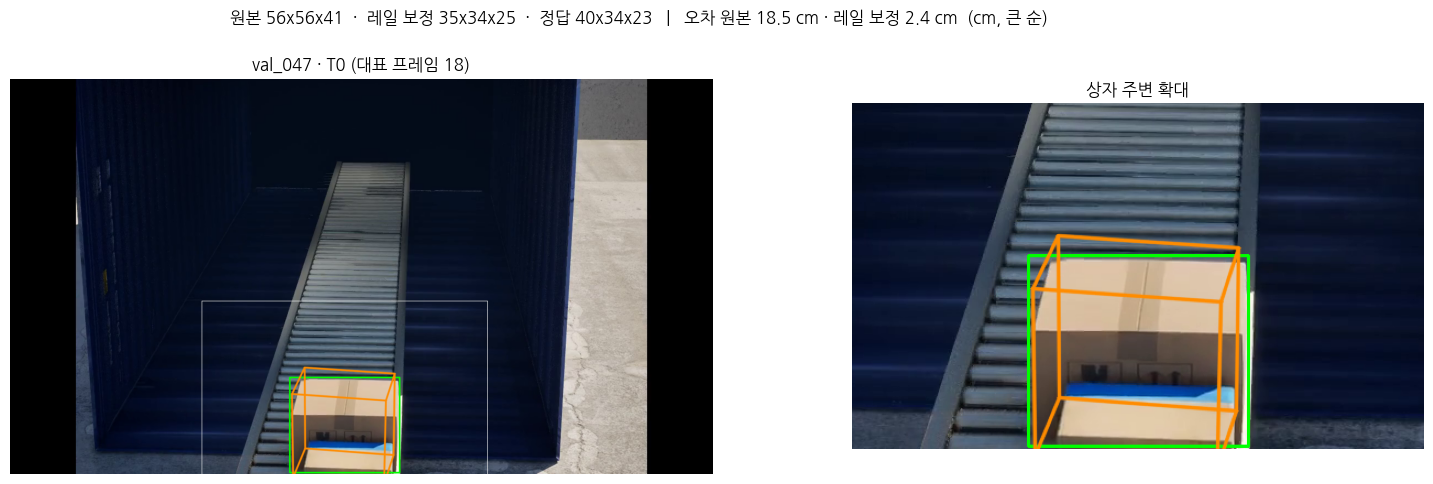

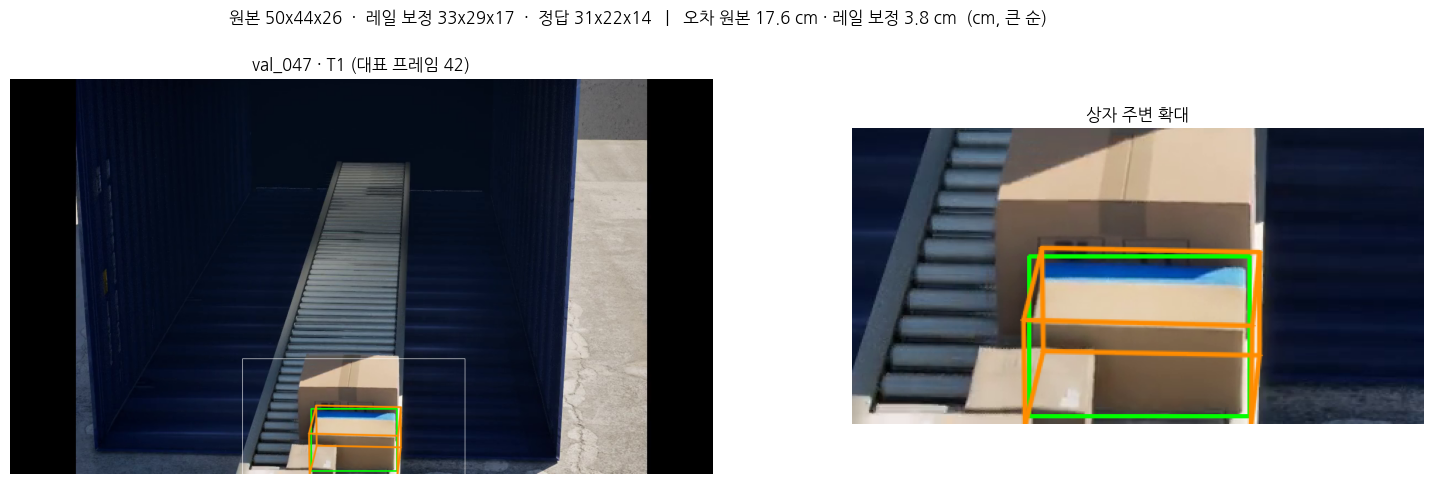

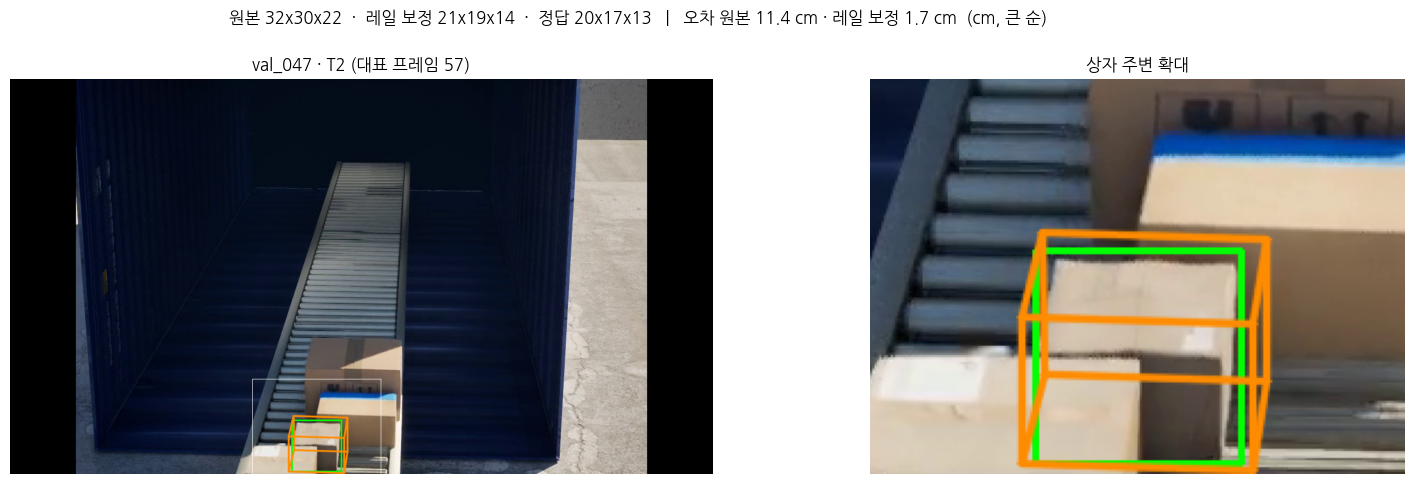

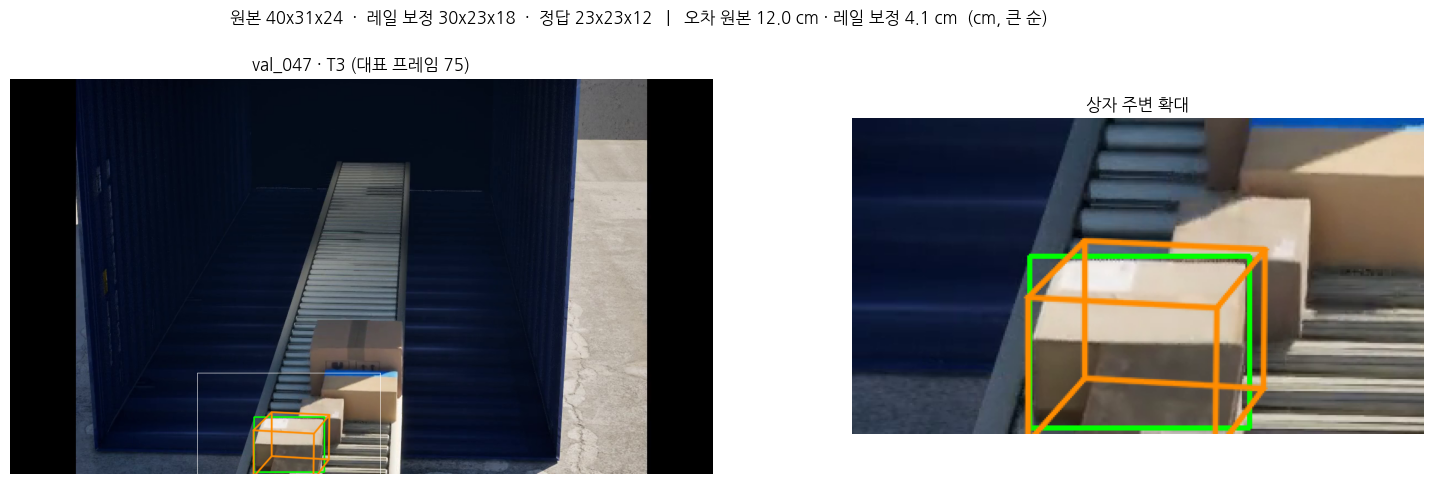

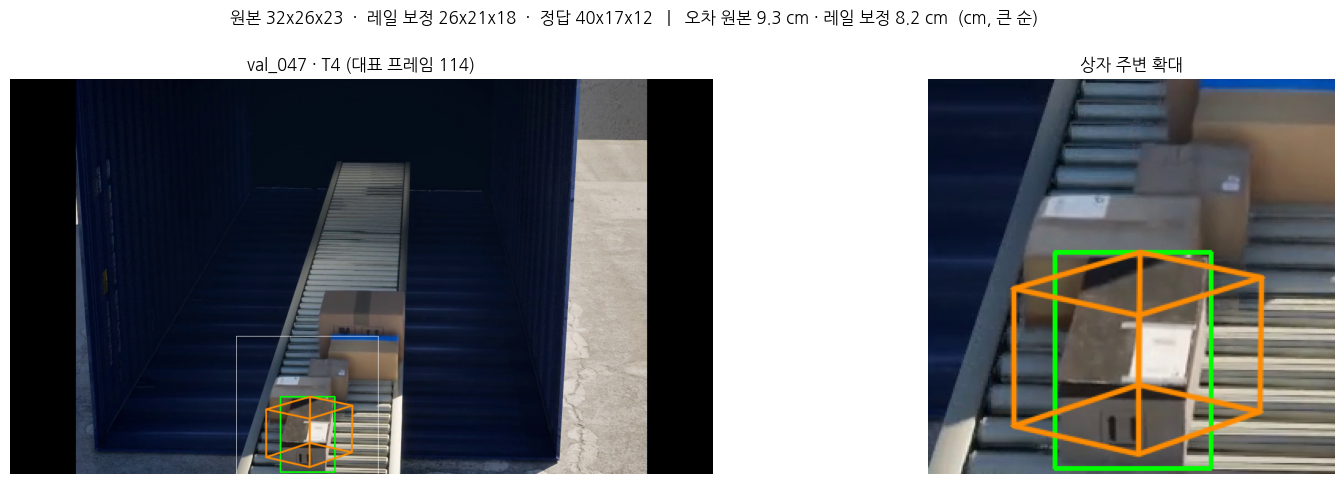

In [ ]:
# [V-1] 한 영상의 모든 상자를 상자마다 따로 (세로로 한 줄씩)
#  - 초록: 우리 트랙 bbox (LIFT 입력) · 주황: LIFT 3D 박스 · 흰 사각형: 오른쪽 확대 영역
#  - 레일 보정은 카메라 중심 기준으로 크기와 거리를 같은 배율로 바꾸므로, 그려진 3D 박스 모양은 보정 전후가 같고 치수 숫자만 바뀐다
VIS_SPLIT = 'val'
ONE_VID = 'val_047'
EDGES12 = [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)]
pred_of = PREDS[VIS_SPLIT].set_index(['vid', 'tid'])
gt_of = PAIRS_ALL[VIS_SPLIT].set_index(['vid', 'tid'])
fmt = lambda a: 'x'.join(f'{v:.0f}' for v in a)
ZOOM_PAD = 0.8                                              # 확대 그림 여백 (bbox 크기 대비)


def draw_one(R, r):
    K = K_of(R['f_px'])
    cap = cv2.VideoCapture(video_path(VIS_SPLIT, R['video_id'])); cap.set(cv2.CAP_PROP_POS_FRAMES, int(r['frame']))
    ok_, img = cap.read(); cap.release()
    x1, y1, x2, y2 = map(int, r['bbox'])
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    P = np.asarray(r['corners'], float); P = P.T if P.shape == (3, 8) else P
    if (P[:, 2] > 0.05).all():
        uv = (K @ P.T).T; uv = np.clip(uv[:, :2] / uv[:, 2:3], -5000, 5000).astype(int)
        for a, b in EDGES12:
            cv2.line(img, (int(uv[a][0]), int(uv[a][1])), (int(uv[b][0]), int(uv[b][1])), (0, 140, 255), 2, cv2.LINE_AA)
    H, W = img.shape[:2]; bw, bh = x2 - x1, y2 - y1
    cx1, cy1 = max(int(x1 - ZOOM_PAD * bw), 0), max(int(y1 - ZOOM_PAD * bh), 0)
    cx2, cy2 = min(int(x2 + ZOOM_PAD * bw), W), min(int(y2 + ZOOM_PAD * bh), H)
    full = img.copy(); cv2.rectangle(full, (cx1, cy1), (cx2, cy2), (255, 255, 255), 1)   # 확대 영역 표시
    return full, img[cy1:cy2, cx1:cx2]


R1 = RAWS[VIS_SPLIT][ONE_VID]
recs = sorted({int(r['tid']): r for r in R1['lift']}.values(), key=lambda r: int(r['tid']))
print(f'{ONE_VID}: 상자(트랙) {len(recs)}개')
for r in recs:
    key = (ONE_VID, int(r['tid']))
    p = pred_of.loc[key] if key in pred_of.index else None
    g = gt_of.loc[key, ['g1', 'g2', 'g3']].values.astype(float) if key in gt_of.index else None
    full, crop = draw_one(R1, r)
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [16, 9]})
    ax[0].imshow(cv2.cvtColor(full, cv2.COLOR_BGR2RGB)); ax[0].set_title(f'{ONE_VID} · T{r["tid"]} (대표 프레임 {r["frame"]})')
    ax[1].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); ax[1].set_title('상자 주변 확대')
    for a in ax:
        a.axis('off')
    if p is not None:
        raw, rail = p[['r1', 'r2', 'r3']].values.astype(float), p[['q1', 'q2', 'q3']].values.astype(float)
        txt = f'원본 {fmt(raw)}  ·  레일 보정 {fmt(rail)}'
        if g is not None:
            txt += f'  ·  정답 {fmt(g)}   |   오차 원본 {np.abs(raw - g).mean():.1f} cm · 레일 보정 {np.abs(rail - g).mean():.1f} cm'
        else:
            txt += '  ·  정답 없음 (매핑되지 않은 트랙)'
        fig.suptitle(txt + '  (cm, 큰 순)', fontsize=12, y=1.0)
    plt.tight_layout()
    plt.show()

# **5. 결과와 해석**

> 숫자는 [Z-1] 최종 요약에 모인다 (L4 GPU · 공식 가중치 · 트랙마다 대표 프레임 1장 · 수작업 매칭 쌍). 제안 방법은 STEP 노트북이 저장한 **개선 STEP 1 + 2-A** 예측을 같은 함수로 채점한 값이며, 제안 방법의 test는 최종 평가 때 한 번만 채점한다.

### 5-1. 지표 ② · ③ ([E-1] · [E-2])
- **LIFT + 레일 보정 (변하지 않는 값):** ② train 6.91 · val 7.12 · test 6.81 cm (36.3 · 36.4 · 35.0%) · ③ train 7.11 · val 7.51 · test 7.24 cm
- **레일 보정은 세 split 모두에서 도움이 된다:** train −2.19 cm · −12.8%p, val −0.56 cm · −5.2%p, test −1.87 cm · −12.0%p. LIFT가 본 거리는 평균적으로 레일과 거의 맞지만 상자마다 흔들림이 커서, 상자별로 바로잡으면 오차가 준다. 다만 세 변에 같은 배율을 곱할 뿐이라 **형태 오차는 남는다.**
- **③ − ② (검출 · 추적의 손해)는 두 방법이 비슷하다** — 같은 트랙을 쓰기 때문. 그래서 두 방법의 차이는 거의 전부 ②(치수 추정)에서 나고, 벌점을 넣어도 순위는 그대로다.

### 5-2. 왜 cm보다 %가 커 보이나 ([E-2b])
- 상자가 작다 (세 변 평균 약 32 · 22 · 14 cm). 같은 2 ~ 3 cm 오차도 짧은 변에서는 %가 크게 잡힌다.
- **LIFT는 중간 변 · 짧은 변을 크게 틀린다** (val 41 ~ 48%). 레일 보정은 짧은 변 · 중간 변을 줄이지만 긴 변은 거의 그대로다 — 형태가 틀린 상자는 배율만으로 못 고친다.
- **납작한 상자(짧은 변 10 cm 이하, 약 4분의 1)일수록 %가 커진다** — 두 방법 모두. 위에서 내려다보면 두께가 거의 안 보이기 때문 → 남은 병목.

### 5-3. 왜 이기는가 — 단계별 사다리 ([E-3])
- w를 개선 STEP 1로 바꾸고 → 형태비를 2-A로 바꾸고 → 형태비를 정답으로 바꾸며 지표 ②가 어떻게 줄어드는지 본다.
- 같은 w에서 형태비만 LIFT 것으로 바꾸면 오차가 크게 늘어난다 → **현장 데이터로 형태비를 따로 학습한 STEP 2가 핵심**이다. LIFT의 바닥 두 변 중 우리 w와 가까운 쪽을 골라준 결과(LIFT에 유리)라 실제 차이는 이보다 작지 않다.

### 5-4. 시각화에서 보이는 것 ([V-1])
- **3D 박스가 bbox보다 크게 그려지는 상자가 많다.** LIFT는 bbox를 특징을 모을 영역으로만 쓰고 중심 · 깊이 · 치수 · 회전을 따로 예측하므로(논문 3.1절), 투영이 bbox에 맞아야 한다는 제약이 없다.
- **납작한 상자의 두께를 크게 잡는다.** 예: val_042 T6 — 정답 22 × 20 × 6 cm → 원본 46 × 39 × 28 · 레일 보정 29 × 25 × 17 cm.
- **레일 보정은 스케일만 고친다.** 예: val_047 T3 — 정답 23 × 23 × 12 cm → 원본 40 × 31 × 24 (오차 12.0 cm) · 레일 보정 30 × 23 × 18 (4.1 cm). 크기는 가까워졌지만 높이는 여전히 정답의 1.5배다.
- 대표 프레임(bbox 면적 최대)은 화면 아래 끝에서 잘릴 수 있다. 제안 방법의 처음 STEP 1 · 2-A도 같은 대표 프레임을 쓴다.

### 5-5. 비용
- 파라미터 **472.7 M** (UniDepthV2-L 353.8 M + LIFT 118.8 M) · L4에서 프레임당 약 **352 ms (2.8 FPS)** = 깊이 146 ms + LIFT 206 ms. 원래 파이프라인은 여기에 Grounding DINO가 더 붙는다.

### 참고 · 한계
- 상대오차는 상자마다 (1/3) Σ |p₍ₖ₎ − g₍ₖ₎| ÷ g₍ₖ₎ × 100의 평균. 벌점 상자는 100% (정답 없는 트랙은 정답이 0이라 100%로 정의).
- LIFT 치수 순서 (W, H, L) 중 H를 높이로 본 것은 Omni3D 규약에 따른 것이다 ([E-3]의 하이브리드에만 쓰임).
- 레일 quad가 없는 영상의 상자에는 같은 split의 레일 배율 중앙값을 쓴다 (GT 미사용).
- 레일 보정에 쓰는 LIFT 깊이는 3D 박스 **중심 깊이**다. bbox 밑변 위치의 꼭짓점 깊이도 시험했으나 val 7.56 cm로 더 나빠 채택하지 않았다.

# **6. 최종 요약**

In [ ]:
# [Z-1] 최종 요약 — 한눈에
print('═' * 90); print('■ 최종 요약 — OVMono3D-LIFT (원본 · + 레일 보정) vs 제안 방법 (개선 STEP 1 + 2-A)')
for sp in [s for s in SPLITS if s in set(RESULT2.split)]:
    R = RESULT2[RESULT2.split == sp].set_index('조건')
    print(f'\n[{sp}]  매칭 쌍 {int(R["매칭 쌍"].iloc[0])} · 미검출 {int(R["미검출"].iloc[0])} · 정답 없는 트랙 {int(R["정답 없는 트랙"].iloc[0])}')
    for name in [o for o in order if o in R.index]:
        r = R.loc[name]
        print(f"  {name:28s} ② {r['② cm']:5.2f} cm · {r['② %']:5.2f}%   ③ {r['③ cm']:5.2f} cm · {r['③ %']:5.2f}%   (③ − ② {r['③ − ② cm']:+.2f} cm)")
    if PROP in R.index:
        a, b = R.loc[VARIANTS[1][0]], R.loc[PROP]
        print(f"  → 제안 방법은 LIFT + 레일 보정의 ② {b['② cm'] / a['② cm']:.2f}배 (cm) · {b['② %'] / a['② %']:.2f}배 (%)  ·  ③ {b['③ cm'] / a['③ cm']:.2f}배 (cm)")
    if 'R3' in globals() and sp in set(R3.split):
        L = R3[R3.split == sp].set_index('단계')['② cm']
        print(f"  사다리 ② cm: LIFT + 레일 {L[LADDER[0]]:.2f} → w = 개선 STEP 1 {L[LADDER[1]]:.2f} → 형태비 = 2-A {L[LADDER[2]]:.2f} → 정답 형태비(하한) {L[LADDER[3]]:.2f}")
print('\n  · 같은 bbox · 대표 프레임 · focal · 레일을 줘도 LIFT는 상자 크기의 3분의 1 넘게 틀린다 — 레일 보정으로 스케일을 고쳐도 형태(비율) 오차가 남음')
print('  · ③ − ② (검출 · 추적의 손해)는 두 방법이 비슷 → 차이는 거의 전부 치수 추정(②)에서 남')
print('  · 비용: LIFT 472.7 M 파라미터 · 2.8 FPS (L4, 깊이 모델 포함)')
print('═' * 90)

══════════════════════════════════════════════════════════════════════════════════════════
■ 최종 요약 — OVMono3D-LIFT (원본 · + 레일 보정) vs 제안 방법 (개선 STEP 1 + 2-A)

[train]  매칭 쌍 899 · 미검출 7 · 정답 없는 트랙 11
  LIFT 원본                      ②  9.10 cm · 49.07%   ③  9.34 cm · 50.07%   (③ − ② +0.23 cm)
  LIFT + 레일 보정                 ②  6.91 cm · 36.25%   ③  7.11 cm · 37.50%   (③ − ② +0.21 cm)
  제안 방법 (개선 STEP 1 + 2-A)      ②  2.22 cm · 11.15%   ③  2.45 cm · 12.89%   (③ − ② +0.23 cm)
  → 제안 방법은 LIFT + 레일 보정의 ② 0.32배 (cm) · 0.31배 (%)  ·  ③ 0.34배 (cm)
  사다리 ② cm: LIFT + 레일 6.91 → w = 개선 STEP 1 4.88 → 형태비 = 2-A 2.22 → 정답 형태비(하한) 0.81

[val]  매칭 쌍 461 · 미검출 6 · 정답 없는 트랙 6
  LIFT 원본                      ②  7.68 cm · 41.60%   ③  8.06 cm · 43.09%   (③ − ② +0.38 cm)
  LIFT + 레일 보정                 ②  7.12 cm · 36.40%   ③  7.51 cm · 38.01%   (③ − ② +0.39 cm)
  제안 방법 (개선 STEP 1 + 2-A)      ②  2.45 cm · 12.88%   ③  2.92 cm · 15.09%   (③ − ② +0.47 cm)
  → 제안 방법은 LIFT + 레일 보정의 ② 0.34배 (cm) · 0.35배 (%)  ·  ③ 0.39배 